# HKH Glacier Mass-Change + ERA5-Land Integration and EDA — Final corrected recovery-data version

**Purpose:** build an auditable monthly ERA5-Land climate table on the Copernicus/WGMS target grid, aggregate the 15 climate predictors into researcher-defined April–March hydrological years, integrate them with glacier mass-change targets, and perform EDA. **No machine-learning model is trained in this notebook.**

## Research rules and correction status
- Target label **Y** means hydrological year **1 April of Y-1 through 31 March of Y**; the interval is `[1 April of Y-1, 1 April of Y)`. Thus target label 2023 means April 2022–March 2023.
- The original ERA5-Land CSV is large and is streamed in chunks. It is not loaded into RAM as one full DataFrame.
- Spatial aggregation uses conservative overlap-area weighting from inferred regular-grid cell bounds. If authoritative NetCDF cell bounds are available, prefer those and compare with the inferred bounds.
- **Correction window:** September 2022 through February 2024 inclusive (18 months), not February 2026.
- The corrected recovery CSV is expected to contain 12 climate variables: `t2m, sf, smlt, ssr, str, ro, es, sro, e, u10, v10, tp`. These replace the original values for matching month + source-grid coordinate. The remaining predictors `snowc, sde, sd` are retained from the original ERA5-Land source because they are not in the corrected CSV.
- Corrected CSV timestamps may be on day 2 (e.g. `2022-09-02`), while the original monthly source may use a different day convention. Therefore replacement keys use **year-month + latitude + longitude**, not exact timestamps.
- The notebook fails loudly if any of the 12 required corrected variables or any required regional month/grid replacement is missing. It does not silently mask a variable or claim a correction where no corrected value exists.
- A successful value replacement audit establishes that values were joined, not by itself that the exported units/forecast-step semantics are scientifically compatible. Confirm the corrected product’s original NetCDF metadata and ECMWF recovery instructions before interpreting annual totals/fluxes as research results.

**Execution status:** this notebook has been edited and statically checked in this environment, but has **not** been executed against the user's local `E:` drive files. Run all cells from top to bottom and inspect the audits before using exported data.


### Critical correction in this final version
The prior v2 notebook accidentally masked the Sep 2022–Feb 2024 issue window to `NaN` **after** the corrected recovery values had already been integrated and audited. That later mask caused the observed pattern (`5` valid months in HY2023 and `1` in HY2024 for affected variables). This final version removes that destructive mask, preserves corrected values, and adds a post-regridding audit for all 12 corrected variables. It still refuses to impute missing climate values as zero.


## 1. Configuration and paths

Check these paths before running. The target file name includes “nepal”, but its observed coordinates may cover a broader Himalayan/HKH region. The notebook reports coordinate bounds and does not silently assume the data is Nepal-only.

In [1]:
from pathlib import Path
from datetime import datetime
import gc, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

TARGET_PATH = Path(r"E:\glacier_research\datasets_to_csv\copernicus_wgms_gridded_mass_change_csv\nepal_glacier_data_1990-2024.csv")
ERA5_PATH = Path(r"E:\glacier_research\datasets_to_csv\era5_land_nepal_climate_1990-2026_csv\data_stream-moda.csv")
CORRECTED_PATH = Path(r"E:\glacier_research\datasets_to_csv\corrected_era5_land_data\combined_corrected_data.csv")
OUTPUT_DIR = Path(r"E:\glacier_research\processed_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Confirmed temporal mapping: target year Y is April Y-1 through March Y.
HY_START_MONTH = 4
TARGET_YEAR_LABEL_MODE = "ending_year"

# Chunk sizes: lower these if RAM remains constrained.
COORD_SCAN_CHUNKSIZE = 1_000_000
DATA_READ_CHUNKSIZE = 500_000

# A broad prefilter only; final source-cell selection uses computed cell overlaps.
# This buffer must be wider than half the source grid spacing. The observed grid
# spacing is checked after the coordinate scan.
SOURCE_PREFILTER_BUFFER_DEG = 1.0

# Minimum accepted geometric overlap. Previous diagnostics for this exact grid found
# a minimum overlap fraction of about 0.7007 at the northern edge. The 0.70 gate
# retains those edge cells while still rejecting cells with less than 70% coverage.
# Review the exported per-cell coverage audit; this is not equivalent to full coverage.
MIN_SPATIAL_COVERAGE = 0.70

# Expected columns, based on prior inspection; change only if the source schema differs.
TARGET_TIME_COL = "time"
TARGET_LAT_COL = "lat"
TARGET_LON_COL = "lon"
TARGET_VALUE_COLS = ["glacier_mass_change_gt", "glacier_mass_change_mwe"]

ERA_TIME_COL = "valid_time"
ERA_LAT_COL = "latitude"
ERA_LON_COL = "longitude"
ERA_VARS = ["t2m", "snowc", "sde", "sd", "sf", "smlt", "ssr", "str", "ro", "es", "sro", "e", "u10", "v10", "tp"]
ERA_METADATA_COLS = ["number", "expver"]  # source metadata, not predictors by default

# Corrected recovery product: all 12 of these columns are required. snowc/sde/sd
# remain sourced from the original ERA5-Land CSV.
CORRECTION_VARS = ["t2m", "sf", "smlt", "ssr", "str", "ro", "es", "sro", "e", "u10", "v10", "tp"]
ISSUE_START = pd.Period("2022-09", freq="M")
ISSUE_END = pd.Period("2024-02", freq="M")  # inclusive

assert TARGET_YEAR_LABEL_MODE == "ending_year"
print("Target mapping: HY Y = [April 1 of Y-1, April 1 of Y), exclusive end")
print("Target CSV:", TARGET_PATH)
print("ERA5-Land CSV:", ERA5_PATH)
print("Output directory:", OUTPUT_DIR)

Target mapping: HY Y = [April 1 of Y-1, April 1 of Y), exclusive end
Target CSV: E:\glacier_research\datasets_to_csv\copernicus_wgms_gridded_mass_change_csv\nepal_glacier_data_1990-2024.csv
ERA5-Land CSV: E:\glacier_research\datasets_to_csv\era5_land_nepal_climate_1990-2026_csv\data_stream-moda.csv
Output directory: E:\glacier_research\processed_data


## 2. Read the target data and audit its schema

The target CSV is comparatively small, so it can be read normally. This section validates required columns, parses year labels, checks duplicate cell-year keys, and reports the actual geographic extent.

In [2]:
for p in [TARGET_PATH, ERA5_PATH, CORRECTED_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Required source file not found: {p}")

def file_info(path):
    st = path.stat()
    return {"path": str(path), "size_bytes": st.st_size,
            "size_GB_decimal": st.st_size / 1e9,
            "modified_time": datetime.fromtimestamp(st.st_mtime).isoformat(timespec="seconds")}

display(pd.DataFrame([file_info(TARGET_PATH), file_info(ERA5_PATH)]))
target = pd.read_csv(TARGET_PATH)
print("Target shape:", target.shape)
print("Target columns:", target.columns.tolist())
display(target.head())
display(target.tail())

required_target = [TARGET_TIME_COL, TARGET_LAT_COL, TARGET_LON_COL]
missing = [c for c in required_target if c not in target.columns]
if missing:
    raise KeyError(f"Required target columns missing: {missing}. Inspect schema and update configuration explicitly.")
for c in [TARGET_LAT_COL, TARGET_LON_COL] + [c for c in TARGET_VALUE_COLS if c in target.columns]:
    target[c] = pd.to_numeric(target[c], errors="coerce")
if target[[TARGET_LAT_COL, TARGET_LON_COL]].isna().any().any():
    raise ValueError("Target latitude/longitude contains missing or nonnumeric values.")

# Confirmed target timestamp/year labels: a timestamp like 1991-01-01 labels HY 1991.
def get_year_label(value):
    dt = pd.to_datetime(value, errors="coerce")
    if pd.notna(dt):
        return int(dt.year)
    return int(pd.to_numeric(value, errors="raise"))

target_periodized = target.copy()
target_periodized["target_year_label"] = target_periodized[TARGET_TIME_COL].apply(get_year_label).astype(int)
target_periodized["period_start"] = pd.to_datetime((target_periodized["target_year_label"] - 1).astype(str) + "-04-01")
target_periodized["period_end_exclusive"] = pd.to_datetime(target_periodized["target_year_label"].astype(str) + "-04-01")
if 1991 in set(target_periodized["target_year_label"]):
    test = target_periodized.loc[target_periodized["target_year_label"] == 1991, ["period_start", "period_end_exclusive"]].drop_duplicates()
    if not ((test["period_start"] == pd.Timestamp("1990-04-01")) & (test["period_end_exclusive"] == pd.Timestamp("1991-04-01"))).all():
        raise RuntimeError("Target year mapping does not match the confirmed HY1991 definition.")

print("Target shape:", target.shape)
print("Target year labels:", target_periodized["target_year_label"].min(), "to", target_periodized["target_year_label"].max())
print("Unique target cells:", target_periodized[[TARGET_LAT_COL, TARGET_LON_COL]].drop_duplicates().shape[0])
print("Target coordinate bounds: latitude", (target[TARGET_LAT_COL].min(), target[TARGET_LAT_COL].max()),
      "longitude", (target[TARGET_LON_COL].min(), target[TARGET_LON_COL].max()))
print("Target rows:", len(target), "exact duplicate rows:", int(target.duplicated().sum()))
cell_year_key = [TARGET_TIME_COL, TARGET_LAT_COL, TARGET_LON_COL]
print("Rows involved in duplicate target cell-year keys:", int(target.duplicated(cell_year_key, keep=False).sum()))
display(target_periodized[[TARGET_TIME_COL, "target_year_label", "period_start", "period_end_exclusive"]].drop_duplicates().sort_values("target_year_label").head(20))

,path,size_bytes,size_GB_decimal,modified_time
0,E:\glacier_research\datasets_to_csv\copernicus...,1973882,0.001974,2026-10-27T09:29:39
1,E:\glacier_research\datasets_to_csv\era5_land_...,9516775046,9.516775,2026-10-27T09:56:31


Target shape: (23698, 9)
Target columns: ['time', 'lat', 'lon', 'glacier_mass_change_gt', 'glacier_mass_change_mwe', 'glacier_area_km2', 'uncertainty_gt', 'uncertainty_mwe', 'spatial_ref']


,time,lat,lon,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,spatial_ref
0,1991-01-01,39.25,67.75,-0.012155,-0.611,19.886,0.001858,0.088,NaN
1,1991-01-01,39.25,68.25,-0.010231,-0.357,28.650,0.003317,0.114,NaN
2,1991-01-01,39.25,68.75,-0.004373,-0.323,13.532,0.002644,0.195,NaN
3,1991-01-01,39.25,69.25,-0.012064,-0.262,46.123,0.002603,0.055,NaN
4,1991-01-01,39.25,69.75,-0.046760,-0.287,162.760,0.004449,0.023,NaN


,time,lat,lon,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,spatial_ref
23693,2024-01-01,27.75,92.75,-0.090054,-1.248,72.172,0.008065,0.093,0.0
23694,2024-01-01,27.75,98.25,-0.000837,-1.528,0.548,0.000329,0.595,0.0
23695,2024-01-01,27.75,98.75,-0.000287,-1.345,0.213,0.000129,0.602,0.0
23696,2024-01-01,27.25,88.75,-0.000448,-1.882,0.238,0.000119,0.490,0.0
23697,2024-01-01,27.25,100.25,-0.009222,-1.710,5.394,0.001247,0.215,0.0


Target shape: (23698, 9)
Target year labels: 1991 to 2024
Unique target cells: 697
Target coordinate bounds: latitude (np.float64(27.25), np.float64(39.25)) longitude (np.float64(67.25), np.float64(103.75))
Target rows: 23698 exact duplicate rows: 0
Rows involved in duplicate target cell-year keys: 0


,time,target_year_label,period_start,period_end_exclusive
0,1991-01-01,1991,1990-04-01,1991-04-01
697,1992-01-01,1992,1991-04-01,1992-04-01
1394,1993-01-01,1993,1992-04-01,1993-04-01
2091,1994-01-01,1994,1993-04-01,1994-04-01
2788,1995-01-01,1995,1994-04-01,1995-04-01
3485,1996-01-01,1996,1995-04-01,1996-04-01
4182,1997-01-01,1997,1996-04-01,1997-04-01
4879,1998-01-01,1998,1997-04-01,1998-04-01
5576,1999-01-01,1999,1998-04-01,1999-04-01
6273,2000-01-01,2000,1999-04-01,2000-04-01


## 3. Target-grid geometry and study-period boundaries

The target grid is defined by the unique target cell-centre coordinates. The source CSV will be filtered to the target period before aggregation. The required ERA period is from April of the earliest target year minus one through March of the latest target year.

In [3]:
def infer_regular_bounds(values, name, atol=1e-6):
    """
    Infer cell boundaries from regularly spaced coordinate centres.

    Parameters
    ----------
    values : iterable
        Coordinate centres, such as a set, list, or NumPy array.
    name : str
        Coordinate name for informative error messages.
    atol : float
        Absolute tolerance for checking regular spacing.

    Returns
    -------
    bounds : dict
        Mapping from coordinate centre to (lower_bound, upper_bound).
    step : float
        Inferred grid spacing in degrees.
    """

    # Convert unordered inputs to a list before creating a Series.
    vals = np.asarray(
        list(values) if isinstance(values, (set, frozenset)) else values
    )

    vals = pd.to_numeric(
        pd.Series(vals),
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    vals = np.sort(np.unique(vals))

    if len(vals) < 2:
        raise ValueError(
            f"Need at least two unique {name} coordinates."
        )

    diffs = np.diff(vals)
    step = float(np.median(diffs))

    if step <= 0:
        raise ValueError(
            f"Invalid coordinate spacing for {name}."
        )

    if not np.allclose(diffs, step, rtol=0, atol=atol):
        unusual = diffs[
            ~np.isclose(diffs, step, rtol=0, atol=atol)
        ]

        raise ValueError(
            f"{name} is not regularly spaced. "
            f"Median step={step}; "
            f"unusual spacing examples={unusual[:10].tolist()}. "
            "Inspect the original grid metadata before proceeding."
        )

    half_step = step / 2.0

    bounds = {
        float(value): (
            float(value - half_step),
            float(value + half_step)
        )
        for value in vals
    }

    return bounds, step

target_lat_bounds, TARGET_DLAT = infer_regular_bounds(target_periodized[TARGET_LAT_COL], "target latitude")
target_lon_bounds, TARGET_DLON = infer_regular_bounds(target_periodized[TARGET_LON_COL], "target longitude")
target_lat_min = min(x[0] for x in target_lat_bounds.values())
target_lat_max = max(x[1] for x in target_lat_bounds.values())
target_lon_min = min(x[0] for x in target_lon_bounds.values())
target_lon_max = max(x[1] for x in target_lon_bounds.values())

MIN_TARGET_YEAR = int(target_periodized["target_year_label"].min())
MAX_TARGET_YEAR = int(target_periodized["target_year_label"].max())
ERA_START = pd.Timestamp(f"{MIN_TARGET_YEAR-1}-04-01")
ERA_END_EXCLUSIVE = pd.Timestamp(f"{MAX_TARGET_YEAR}-04-01")
print("Target cell steps:", TARGET_DLAT, "latitude degrees;", TARGET_DLON, "longitude degrees")
print("Target grid outer bounds:", (target_lat_min, target_lat_max, target_lon_min, target_lon_max))
print("ERA date filter:", ERA_START, "through", ERA_END_EXCLUSIVE, "(exclusive end)")
if target_lat_min < 20 or target_lat_max > 45 or target_lon_min < 60 or target_lon_max > 110:
    warnings.warn("Target coordinates extend beyond a narrow Nepal-only bounding box. Confirm whether the target represents the broader HKH region; do not rename the study area without checking provenance.")

Target cell steps: 0.5 latitude degrees; 0.5 longitude degrees
Target grid outer bounds: (27.0, 39.5, 67.0, 104.0)
ERA date filter: 1990-04-01 00:00:00 through 2024-04-01 00:00:00 (exclusive end)


## 4. Stream-scan ERA5 coordinates (do not load the 9.5 GB CSV)

The source file previously contained about 47 million rows and required more than 7 GB when loaded as a full DataFrame. This first pass reads **only latitude and longitude columns in chunks**, retaining unique coordinate values rather than all rows. Those coordinate centres are used to verify the source grid spacing and infer provisional cell bounds.

If the coordinate spacing is irregular, stop and use authoritative cell bounds from the original NetCDF instead of proceeding with inferred bounds.

In [4]:
# Read only coordinate columns in chunks; do not assign the full ERA CSV to `era`.
coord_lat_values = set()
coord_lon_values = set()
coord_rows_scanned = 0
for chunk in pd.read_csv(ERA5_PATH, usecols=[ERA_LAT_COL, ERA_LON_COL], chunksize=COORD_SCAN_CHUNKSIZE):
    lat = pd.to_numeric(chunk[ERA_LAT_COL], errors="coerce")
    lon = pd.to_numeric(chunk[ERA_LON_COL], errors="coerce")
    valid = lat.notna() & lon.notna()
    coord_rows_scanned += len(chunk)
    # Broad regional prefilter reduces coordinate sets; final selection uses exact overlaps.
    keep = valid & lat.between(target_lat_min - SOURCE_PREFILTER_BUFFER_DEG,
                               target_lat_max + SOURCE_PREFILTER_BUFFER_DEG) & \
                  lon.between(target_lon_min - SOURCE_PREFILTER_BUFFER_DEG,
                              target_lon_max + SOURCE_PREFILTER_BUFFER_DEG)
    coord_lat_values.update(lat.loc[keep].astype(float).unique().tolist())
    coord_lon_values.update(lon.loc[keep].astype(float).unique().tolist())
    del chunk, lat, lon, valid, keep
    gc.collect()

print("Coordinate rows scanned (all source rows):", f"{coord_rows_scanned:,}")
print("Unique regional source latitude centres:", len(coord_lat_values))
print("Unique regional source longitude centres:", len(coord_lon_values))
if not coord_lat_values or not coord_lon_values:
    raise RuntimeError("No source coordinates found near the target domain. Check coordinate columns and target extent.")

source_lat_bounds, SOURCE_DLAT = infer_regular_bounds(
    sorted(coord_lat_values),
    "regional ERA5 latitude"
)

source_lon_bounds, SOURCE_DLON = infer_regular_bounds(
    sorted(coord_lon_values),
    "regional ERA5 longitude"
)

print("Inferred source grid steps:", SOURCE_DLAT, "latitude degrees;", SOURCE_DLON, "longitude degrees")
if SOURCE_PREFILTER_BUFFER_DEG <= max(SOURCE_DLAT, SOURCE_DLON) / 2:
    raise RuntimeError("Source prefilter buffer is not larger than half the source grid spacing. Increase it and rerun this section.")
print("Source latitude centre range:", min(source_lat_bounds), "to", max(source_lat_bounds))
print("Source longitude centre range:", min(source_lon_bounds), "to", max(source_lon_bounds))

Coordinate rows scanned (all source rows): 47,159,565
Unique regional source latitude centres: 133
Unique regional source longitude centres: 390
Inferred source grid steps: 0.10000000000000142 latitude degrees; 0.09999999999999432 longitude degrees
Source latitude centre range: 26.09999999999981 to 39.3
Source longitude centre range: 66.09999999999992 to 105.0


## 5. Build conservative source–target overlap geometry

For each target cell, only source latitude bands and longitude bands that geometrically intersect it are considered. This avoids the previous nested loop over every source and target cell combination. On a spherical Earth, the area factor for a lat/lon rectangle is proportional to `Δlongitude × (sin(north latitude) − sin(south latitude))`; the common Earth-radius-squared factor cancels in weighted means.

In [5]:
def area_factor(lat_s, lat_n, lon_w, lon_e):
    lat_s, lat_n = np.deg2rad(lat_s), np.deg2rad(lat_n)
    lon_w, lon_e = np.deg2rad(lon_w), np.deg2rad(lon_e)
    return abs(lon_e - lon_w) * abs(np.sin(lat_n) - np.sin(lat_s))

def build_overlap_fast(src_lat_bounds, src_lon_bounds, tgt_lat_bounds, tgt_lon_bounds):
    rows = []
    src_lat_items = list(src_lat_bounds.items())
    src_lon_items = list(src_lon_bounds.items())
    # Cache source bands intersecting each target latitude/longitude interval.
    lat_candidates = {}
    for tlat, (ts, tn) in tgt_lat_bounds.items():
        lat_candidates[tlat] = [(slat, ss, sn, max(ts, ss), min(tn, sn))
                                for slat, (ss, sn) in src_lat_items if min(tn, sn) > max(ts, ss)]
    lon_candidates = {}
    for tlon, (tw, te) in tgt_lon_bounds.items():
        lon_candidates[tlon] = [(slon, sw, se, max(tw, sw), min(te, se))
                                for slon, (sw, se) in src_lon_items if min(te, se) > max(tw, sw)]
    for tlat, (ts, tn) in tgt_lat_bounds.items():
        for tlon, (tw, te) in tgt_lon_bounds.items():
            for slat, ss, sn, os_, on in lat_candidates[tlat]:
                for slon, sw, se, ow, oe in lon_candidates[tlon]:
                    a = area_factor(os_, on, ow, oe)
                    if a > 0:
                        rows.append({"target_latitude": tlat, "target_longitude": tlon,
                                     "source_latitude": slat, "source_longitude": slon,
                                     "overlap_area_factor": a})
    return pd.DataFrame(rows)

overlap = build_overlap_fast(source_lat_bounds, source_lon_bounds, target_lat_bounds, target_lon_bounds)
if overlap.empty:
    raise RuntimeError("No spatial overlaps found. Check coordinate systems, bounds, and target extent.")
if (overlap["overlap_area_factor"] <= 0).any():
    raise AssertionError("Non-positive overlap area detected.")
overlap_key = ["source_latitude", "source_longitude", "target_latitude", "target_longitude"]
if overlap.duplicated(overlap_key).any():
    raise RuntimeError("Duplicate source-target overlap pairs were created.")
source_pairs = overlap[["source_latitude", "source_longitude"]].drop_duplicates().copy()
print("Source-target overlap pairs:", f"{len(overlap):,}")
print("Unique ERA source cells needed:", f"{len(source_pairs):,}")
display(overlap.head())

Source-target overlap pairs: 65,712
Unique ERA source cells needed: 46,004


,target_latitude,target_longitude,source_latitude,source_longitude,overlap_area_factor
0,27.25,67.25,27.0,67.0,6.783893e-07
1,27.25,67.25,27.0,67.1,1.356779e-06
2,27.25,67.25,27.0,67.2,1.356779e-06
3,27.25,67.25,27.0,67.3,1.356779e-06
4,27.25,67.25,27.0,67.4,1.356779e-06


## 6. Read only relevant ERA5 records in chunks

This second pass reads the required time, coordinates, and climate columns. Each chunk is filtered to the target study period and to **exact source coordinate pairs that intersect at least one target cell**. It does not read all 47 million rows into RAM. The selected regional data are retained in memory; if this is still too large, the next optimization is to regrid directly while streaming each time chunk rather than concatenate the regional records.

In [6]:
era_header = pd.read_csv(ERA5_PATH, nrows=0).columns.tolist()
required_era_cols = [ERA_TIME_COL, ERA_LAT_COL, ERA_LON_COL] + ERA_VARS
missing_era_required = [c for c in required_era_cols if c not in era_header]
if missing_era_required:
    raise KeyError(
        "The ERA5-Land CSV is missing required columns: "
        f"{missing_era_required}. Check the source export/header; no variables will be silently dropped."
    )
era_usecols = required_era_cols
variables_present = ERA_VARS.copy()
print("All expected climate variables found:", variables_present)
print("Reading columns:", era_usecols)

# Use a MultiIndex of exact floating coordinate pairs; no rounding/nearest-neighbour matching.
source_pair_index = pd.MultiIndex.from_frame(source_pairs.rename(columns={"source_latitude": ERA_LAT_COL,
                                                                         "source_longitude": ERA_LON_COL}))
regional_parts = []
source_rows_scanned_second_pass = 0
regional_rows_kept = 0
for chunk_i, chunk in enumerate(pd.read_csv(ERA5_PATH, usecols=era_usecols, chunksize=DATA_READ_CHUNKSIZE), start=1):
    source_rows_scanned_second_pass += len(chunk)
    chunk[ERA_TIME_COL] = pd.to_datetime(chunk[ERA_TIME_COL], errors="coerce")
    chunk[ERA_LAT_COL] = pd.to_numeric(chunk[ERA_LAT_COL], errors="coerce")
    chunk[ERA_LON_COL] = pd.to_numeric(chunk[ERA_LON_COL], errors="coerce")
    keep_time = chunk[ERA_TIME_COL].ge(ERA_START) & chunk[ERA_TIME_COL].lt(ERA_END_EXCLUSIVE)
    keep_bbox = chunk[ERA_LAT_COL].between(min(source_lat_bounds), max(source_lat_bounds)) & \
                chunk[ERA_LON_COL].between(min(source_lon_bounds), max(source_lon_bounds))
    candidates = chunk.loc[keep_time & keep_bbox].copy()
    if not candidates.empty:
        candidate_index = pd.MultiIndex.from_arrays([candidates[ERA_LAT_COL].to_numpy(), candidates[ERA_LON_COL].to_numpy()])
        candidates = candidates.loc[candidate_index.isin(source_pair_index)]
        if not candidates.empty:
            regional_rows_kept += len(candidates)
            regional_parts.append(candidates)
    del chunk, candidates
    if chunk_i % 20 == 0:
        print(f"Chunks scanned: {chunk_i}; regional rows retained so far: {regional_rows_kept:,}")
    gc.collect()

if not regional_parts:
    raise RuntimeError("No ERA rows matched the target period and overlapping source cells.")
era_region = pd.concat(regional_parts, ignore_index=True)
del regional_parts
for v in variables_present:
    era_region[v] = pd.to_numeric(era_region[v], errors="coerce")
if era_region[ERA_TIME_COL].isna().any():
    raise RuntimeError("Invalid ERA timestamps remain after chunked loading.")
source_key = [ERA_TIME_COL, ERA_LAT_COL, ERA_LON_COL]
dup_count = int(era_region.duplicated(source_key, keep=False).sum())
print("Source rows scanned in second pass:", f"{source_rows_scanned_second_pass:,}")
print("Regional ERA rows retained:", f"{len(era_region):,}")
print("Regional ERA memory (GB):", round(era_region.memory_usage(deep=True).sum()/1024**3, 3))
print("Duplicate time/source-cell rows:", f"{dup_count:,}")
if dup_count:
    display(era_region.loc[era_region.duplicated(source_key, keep=False), source_key].head(30))
    raise RuntimeError("Duplicate ERA time/source-cell keys detected. Inspect expver or other source dimensions; do not average silently.")

# ---- Replace all 12 available climate variables for Sep 2022-Feb 2024 ----
# Join on month + rounded coordinates because the recovery CSV may use day 2 of
# each month while the original monthly CSV uses a different timestamp day.
correction_header = pd.read_csv(CORRECTED_PATH, nrows=0).columns.tolist()
required_correction = ["valid_time", "latitude", "longitude"] + CORRECTION_VARS
missing_corr = [c for c in required_correction if c not in correction_header]
if missing_corr:
    raise KeyError(
        "Corrected CSV does not contain all 12 required climate variables. "
        f"Missing: {missing_corr}. Expected columns include {required_correction}. "
        "Do not proceed with a partial correction file."
    )

# Read only necessary columns and only the 18-month recovery window. This avoids
# loading unrelated metadata or columns from the corrected file.
correction_parts = []
for corr_chunk in pd.read_csv(CORRECTED_PATH, usecols=required_correction, chunksize=DATA_READ_CHUNKSIZE):
    corr_chunk["valid_time"] = pd.to_datetime(corr_chunk["valid_time"], errors="coerce")
    corr_chunk["latitude"] = pd.to_numeric(corr_chunk["latitude"], errors="coerce")
    corr_chunk["longitude"] = pd.to_numeric(corr_chunk["longitude"], errors="coerce")
    corr_chunk["month_period"] = corr_chunk["valid_time"].dt.to_period("M")
    corr_chunk = corr_chunk.loc[corr_chunk["month_period"].between(ISSUE_START, ISSUE_END)].copy()
    if not corr_chunk.empty:
        for v in CORRECTION_VARS:
            corr_chunk[v] = pd.to_numeric(corr_chunk[v], errors="coerce")
        corr_chunk["_lat_key"] = corr_chunk["latitude"].round(6)
        corr_chunk["_lon_key"] = corr_chunk["longitude"].round(6)
        correction_parts.append(corr_chunk[["month_period", "_lat_key", "_lon_key"] + CORRECTION_VARS])
    del corr_chunk
    gc.collect()
if not correction_parts:
    raise RuntimeError("No rows from Sep 2022-Feb 2024 found in corrected recovery CSV.")
correction = pd.concat(correction_parts, ignore_index=True)
del correction_parts
correction = correction.rename(columns={"month_period": "_month_period_corr"})
if correction.duplicated(["_month_period_corr", "_lat_key", "_lon_key"]).any():
    dup = correction.loc[correction.duplicated(["_month_period_corr", "_lat_key", "_lon_key"], keep=False)]
    display(dup.head(20))
    raise RuntimeError("Corrected source has duplicate month-coordinate keys; do not average them silently.")

# Restrict correction records to the exact regional source-cell keys that survived
# the spatial prefilter. Missing replacements are a hard error, not a silent fallback.
source_pair_keys = source_pairs.rename(columns={"source_latitude": "_lat_key", "source_longitude": "_lon_key"}).copy()
source_pair_keys["_lat_key"] = source_pair_keys["_lat_key"].round(6)
source_pair_keys["_lon_key"] = source_pair_keys["_lon_key"].round(6)
correction = correction.merge(source_pair_keys.drop_duplicates(), on=["_lat_key", "_lon_key"], how="inner", validate="many_to_one")

# Use the original source month and coordinates as the left side. This preserves
# all original regional records, while replacing values only where a corrected value
# exists and the row falls inside the documented 18-month window.
era_region["_month_period_corr"] = era_region[ERA_TIME_COL].dt.to_period("M")
era_region["_lat_key"] = era_region[ERA_LAT_COL].round(6)
era_region["_lon_key"] = era_region[ERA_LON_COL].round(6)
correction = correction.rename(columns={v: f"{v}__corrected" for v in CORRECTION_VARS})
era_region = era_region.merge(
    correction, left_on=["_month_period_corr", "_lat_key", "_lon_key"],
    right_on=["_month_period_corr", "_lat_key", "_lon_key"],
    how="left", validate="many_to_one", suffixes=("", "__corrkey")
)

correction_audit_rows = []
issue_mask = era_region["_month_period_corr"].between(ISSUE_START, ISSUE_END)
for v in CORRECTION_VARS:
    replacement_col = f"{v}__corrected"
    has_replacement = era_region[replacement_col].notna()
    replace_mask = issue_mask & has_replacement
    missing_mask = issue_mask & ~has_replacement
    correction_audit_rows.append({
        "variable": v,
        "rows_in_issue_window": int(issue_mask.sum()),
        "rows_replaced": int(replace_mask.sum()),
        "affected_rows_without_replacement": int(missing_mask.sum()),
        "corrected_values_missing_after_join": int((issue_mask & era_region[replacement_col].isna()).sum()),
        "source": str(CORRECTED_PATH),
    })
    era_region.loc[replace_mask, v] = era_region.loc[replace_mask, replacement_col]
correction_audit = pd.DataFrame(correction_audit_rows)
print("Corrected-source replacement audit (all 12 variables; 18-month window):")
display(correction_audit)
if (correction_audit["affected_rows_without_replacement"] > 0).any():
    bad = correction_audit.loc[correction_audit["affected_rows_without_replacement"] > 0]
    raise RuntimeError(
        "Some regional source rows in Sep 2022-Feb 2024 lack corrected values. "
        "Do not proceed until grid/month coverage is resolved. Audit rows:\n" + bad.to_string(index=False)
    )

# Keep only original ERA variables plus timestamp/coordinates; corrected values have
# already replaced the corresponding source fields.
era_region = era_region.drop(columns=["_month_period_corr", "_lat_key", "_lon_key"] +
                             [f"{v}__corrected" for v in CORRECTION_VARS])

print("Regional time range:", era_region[ERA_TIME_COL].min(), "to", era_region[ERA_TIME_COL].max())
print("Regional unique months:", era_region[ERA_TIME_COL].dt.to_period("M").nunique())
display(era_region.head())

All expected climate variables found: ['t2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp']
Reading columns: ['valid_time', 'latitude', 'longitude', 't2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp']
Chunks scanned: 20; regional rows retained so far: 3,731,246
Chunks scanned: 40; regional rows retained so far: 8,152,614
Chunks scanned: 60; regional rows retained so far: 12,573,932
Chunks scanned: 80; regional rows retained so far: 16,995,278
Source rows scanned in second pass: 47,159,565
Regional ERA rows retained: 18,769,632
Regional ERA memory (GB): 2.517
Duplicate time/source-cell rows: 0
Corrected-source replacement audit (all 12 variables; 18-month window):


,variable,rows_in_issue_window,rows_replaced,affected_rows_without_replacement,corrected_values_missing_after_join,source
0,t2m,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
1,sf,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
2,smlt,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
3,ssr,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
4,str,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
5,ro,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
6,es,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
7,sro,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
8,e,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
9,u10,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...


Regional time range: 1990-04-01 00:00:00 to 2024-03-01 00:00:00
Regional unique months: 408


,valid_time,latitude,longitude,t2m,snowc,sde,sd,sf,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
0,1990-04-01,39.3,67.0,281.79750,0.001953,-7.345365e-24,-7.345365e-25,0.000000,3.837049e-07,14911974.0,-5181354.0,0.000984,-1.164153e-10,0.000641,-0.002546,-0.068126,0.330959,0.005362
1,1990-04-01,39.3,67.1,281.26233,0.066406,-7.345365e-24,1.144409e-05,0.000012,1.345202e-05,15067322.0,-5475755.0,0.001077,1.583248e-08,0.000883,-0.002380,-0.019298,0.465725,0.004870
2,1990-04-01,39.3,67.2,280.36975,1.072266,9.765625e-04,1.811981e-04,0.000166,1.908634e-04,15371254.0,-5720010.0,0.001244,2.200250e-08,0.001136,-0.002340,-0.014903,0.595608,0.004556
3,1990-04-01,39.3,67.3,278.84045,16.369140,2.832031e-02,8.172035e-03,0.000513,2.350248e-03,14808356.0,-5544798.0,0.002266,-1.842622e-06,0.001643,-0.001978,-0.060313,0.715237,0.004454
4,1990-04-01,39.3,67.4,277.15686,47.847656,1.435547e-01,4.498577e-02,0.000833,5.922778e-03,12299188.0,-4644609.0,0.003921,-1.472549e-05,0.003027,-0.001351,-0.109141,0.826565,0.004327


## 7. Geometric coverage diagnostics and approval gate

Geometric overlap fraction measures how much of each target cell is covered by the selected source grid, independently of missing climate values. Review the histogram and the lowest-coverage cells. **Do not set a threshold merely to bypass the gate.** If all target cells are fully covered (within numerical tolerance), a threshold of 0.99 or 1.0 may be reasonable, but the actual diagnostics must guide the choice.

Geometric overlap fraction summary:


count    697.000000
mean       0.988837
std        0.056750
min        0.700749
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: geometry_overlap_fraction, dtype: float64

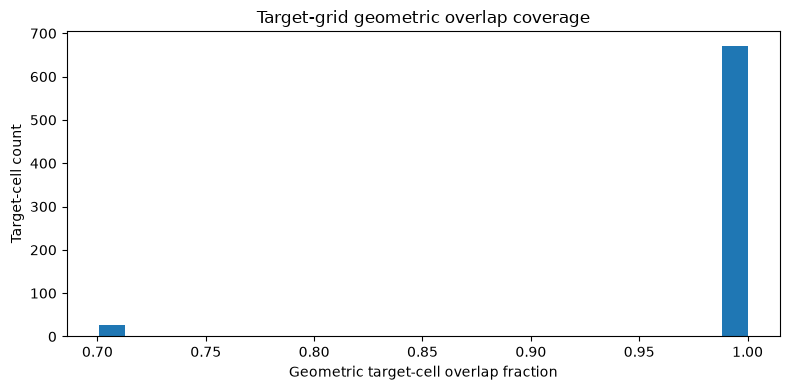

Lowest-coverage target cells:


,target_latitude,target_longitude,target_area_factor,overlap_area_factor,geometry_overlap_fraction
1,39.25,68.25,0.000059,0.000041,0.700749
3,39.25,69.25,0.000059,0.000041,0.700749
5,39.25,70.25,0.000059,0.000041,0.700749
4,39.25,69.75,0.000059,0.000041,0.700749
9,39.25,72.25,0.000059,0.000041,0.700749
13,39.25,74.25,0.000059,0.000041,0.700749
22,39.25,97.75,0.000059,0.000041,0.700749
24,39.25,98.75,0.000059,0.000041,0.700749
19,39.25,96.25,0.000059,0.000041,0.700749
21,39.25,97.25,0.000059,0.000041,0.700749


Approved geometric coverage threshold: 0.7
Target cells passing threshold: 697 / 697


In [7]:
target_cells = target_periodized[[TARGET_LAT_COL, TARGET_LON_COL]].drop_duplicates().rename(
    columns={TARGET_LAT_COL: "target_latitude", TARGET_LON_COL: "target_longitude"})
target_cells["target_area_factor"] = [
    area_factor(target_lat_bounds[float(r.target_latitude)][0], target_lat_bounds[float(r.target_latitude)][1],
                target_lon_bounds[float(r.target_longitude)][0], target_lon_bounds[float(r.target_longitude)][1])
    for r in target_cells.itertuples(index=False)
]
overlap_sum = overlap.groupby(["target_latitude", "target_longitude"], as_index=False)["overlap_area_factor"].sum()
geometry_coverage = target_cells.merge(overlap_sum, on=["target_latitude", "target_longitude"], how="left")
geometry_coverage["geometry_overlap_fraction"] = geometry_coverage["overlap_area_factor"] / geometry_coverage["target_area_factor"]
print("Geometric overlap fraction summary:")
display(geometry_coverage["geometry_overlap_fraction"].describe())
plt.figure(figsize=(8,4))
plt.hist(geometry_coverage["geometry_overlap_fraction"].dropna(), bins=25)
plt.xlabel("Geometric target-cell overlap fraction")
plt.ylabel("Target-cell count")
plt.title("Target-grid geometric overlap coverage")
plt.tight_layout(); plt.show()
print("Lowest-coverage target cells:")
display(geometry_coverage.sort_values("geometry_overlap_fraction").head(25))

if MIN_SPATIAL_COVERAGE is None:
    raise RuntimeError("STOP: review geometric coverage results, set MIN_SPATIAL_COVERAGE in Section 1, then rerun this cell and subsequent cells.")
if not 0 < float(MIN_SPATIAL_COVERAGE) <= 1:
    raise ValueError("MIN_SPATIAL_COVERAGE must be in (0, 1].")
geometry_coverage["passes_geometry_threshold"] = geometry_coverage["geometry_overlap_fraction"] >= float(MIN_SPATIAL_COVERAGE)
print("Approved geometric coverage threshold:", MIN_SPATIAL_COVERAGE)
print("Target cells passing threshold:", int(geometry_coverage["passes_geometry_threshold"].sum()), "/", len(geometry_coverage))
if not geometry_coverage["passes_geometry_threshold"].all():
    print("Cells below threshold are retained in the audit but excluded from climate aggregation.")

## 8. Monthly conservative spatial aggregation (memory-conscious)

Only source cells that overlap target cells are in `era_region`. This cell expands one month at a time, calculates overlap-area-weighted means and per-variable valid-area coverage, and then releases the monthly intermediate data. Target cells that fail the approved geometric threshold are not assigned climate features; they remain in the target dataset and can be reported as unmatched later.

In [8]:
start_time = time.time()
valid_target_cells = geometry_coverage.loc[geometry_coverage["passes_geometry_threshold"],
                                           ["target_latitude", "target_longitude"]]
valid_target_index = pd.MultiIndex.from_frame(valid_target_cells)
ov = overlap.merge(valid_target_cells, on=["target_latitude", "target_longitude"], how="inner", validate="many_to_one")
cell_keys = ["target_latitude", "target_longitude"]
static_metrics = ov.groupby(cell_keys, sort=False).agg(
    overlap_area_factor_total=("overlap_area_factor", "sum"),
    n_overlapping_source_cells=("source_latitude", "size")
)

# Verify month-level source uniqueness and determine observed monthly timestamps.
era_region["_month_period"] = era_region[ERA_TIME_COL].dt.to_period("M")
month_periods = sorted(era_region["_month_period"].dropna().unique())
print("Months to process:", len(month_periods))
print("Regional source rows:", f"{len(era_region):,}")
print("Overlap pairs after geometry gate:", f"{len(ov):,}")
monthly_parts = []

for month_i, month in enumerate(month_periods, start=1):
    month_data = era_region.loc[era_region["_month_period"] == month].drop(columns="_month_period")
    joined_month = month_data.merge(
        ov.rename(columns={"source_latitude": ERA_LAT_COL, "source_longitude": ERA_LON_COL}),
        on=[ERA_LAT_COL, ERA_LON_COL], how="inner", validate="many_to_many", sort=False
    )
    if joined_month.empty:
        print(f"WARNING: no overlap rows for {month}; month omitted from monthly table")
        del month_data, joined_month
        continue
    group_keys = [ERA_TIME_COL, "target_latitude", "target_longitude"]
    base_groups = joined_month[group_keys].drop_duplicates()
    pieces = []
    for v in variables_present:
        vals = pd.to_numeric(joined_month[v], errors="coerce")
        valid_mask = np.isfinite(vals.to_numpy(dtype=float))
        if not valid_mask.any():
            continue
        vr = joined_month.loc[valid_mask, group_keys + ["overlap_area_factor"]].copy()
        vr["_weighted_numerator"] = vals.loc[valid_mask].to_numpy(dtype=float) * vr["overlap_area_factor"].to_numpy(dtype=float)
        agg = vr.groupby(group_keys, sort=False).agg(
            **{f"{v}__numerator": ("_weighted_numerator", "sum"),
               f"{v}__valid_area_factor": ("overlap_area_factor", "sum")}
        )
        agg[v] = agg[f"{v}__numerator"] / agg[f"{v}__valid_area_factor"].replace(0, np.nan)
        area_denominator = static_metrics["overlap_area_factor_total"].reindex(
            pd.MultiIndex.from_frame(agg.reset_index()[cell_keys])
        ).to_numpy()
        agg[f"{v}__coverage_fraction"] = agg[f"{v}__valid_area_factor"].to_numpy() / area_denominator
        agg = agg.drop(columns=[f"{v}__numerator"])
        pieces.append(agg)
    if pieces:
        agg_all = pd.concat(pieces, axis=1).reset_index()
        month_result = base_groups.merge(agg_all, on=group_keys, how="left", validate="one_to_one")
    else:
        month_result = base_groups.copy()
    month_result = month_result.merge(static_metrics.reset_index(), on=cell_keys, how="left", validate="many_to_one")
    month_result["timestamp"] = pd.to_datetime(month_result[ERA_TIME_COL])
    month_result["month_period"] = month_result["timestamp"].dt.to_period("M")
    month_result["days_in_month"] = month_result["timestamp"].dt.days_in_month
    monthly_parts.append(month_result)
    del month_data, joined_month, base_groups, pieces, month_result
    if month_i % 12 == 0 or month_i == len(month_periods):
        print(f"Processed {month_i}/{len(month_periods)} months; elapsed {time.time()-start_time:.1f}s")
    gc.collect()

if not monthly_parts:
    raise RuntimeError("No monthly spatial results produced. Check source coordinate matching and overlap geometry.")
monthly_spatial = pd.concat(monthly_parts, ignore_index=True)
del monthly_parts
gc.collect()

# Keep a stable schema: every requested predictor is present even if source values
# are entirely missing for a variable. Missing values remain NaN, never zero-filled.
for v in ERA_VARS:
    if v not in monthly_spatial.columns:
        monthly_spatial[v] = np.nan
    for suffix in ("__coverage_fraction", "__valid_area_factor"):
        col = f"{v}{suffix}"
        if col not in monthly_spatial.columns:
            monthly_spatial[col] = np.nan

monthly_spatial = monthly_spatial.sort_values(["timestamp", "target_latitude", "target_longitude"]).reset_index(drop=True)
print("Monthly spatial dataset shape:", monthly_spatial.shape)
print("Elapsed seconds:", round(time.time()-start_time, 1))
display(monthly_spatial.head())

# No issue-window masking is applied here: all 12 corrected variables, including tp,
# were replaced and audited in Section 6 before spatial aggregation. snowc/sde/sd
# are retained from the original ERA5-Land source by design.


Months to process: 408
Regional source rows: 18,769,632
Overlap pairs after geometry gate: 24,780
Processed 12/408 months; elapsed 4.1s
Processed 24/408 months; elapsed 7.2s
Processed 36/408 months; elapsed 10.4s
Processed 48/408 months; elapsed 13.6s
Processed 60/408 months; elapsed 16.7s
Processed 72/408 months; elapsed 19.8s
Processed 84/408 months; elapsed 23.0s
Processed 96/408 months; elapsed 26.2s
Processed 108/408 months; elapsed 29.4s
Processed 120/408 months; elapsed 32.8s
Processed 132/408 months; elapsed 36.7s
Processed 144/408 months; elapsed 40.3s
Processed 156/408 months; elapsed 43.9s
Processed 168/408 months; elapsed 47.3s
Processed 180/408 months; elapsed 50.7s
Processed 192/408 months; elapsed 54.1s
Processed 204/408 months; elapsed 57.6s
Processed 216/408 months; elapsed 61.2s
Processed 228/408 months; elapsed 64.7s
Processed 240/408 months; elapsed 68.5s
Processed 252/408 months; elapsed 72.1s
Processed 264/408 months; elapsed 75.8s
Processed 276/408 months; elapse

,valid_time,target_latitude,target_longitude,t2m__valid_area_factor,t2m,t2m__coverage_fraction,snowc__valid_area_factor,snowc,snowc__coverage_fraction,sde__valid_area_factor,sde,sde__coverage_fraction,sd__valid_area_factor,sd,sd__coverage_fraction,sf__valid_area_factor,sf,sf__coverage_fraction,smlt__valid_area_factor,smlt,smlt__coverage_fraction,ssr__valid_area_factor,ssr,ssr__coverage_fraction,str__valid_area_factor,str,str__coverage_fraction,ro__valid_area_factor,ro,ro__coverage_fraction,es__valid_area_factor,es,es__coverage_fraction,sro__valid_area_factor,sro,sro__coverage_fraction,e__valid_area_factor,e,e__coverage_fraction,u10__valid_area_factor,u10,u10__coverage_fraction,v10__valid_area_factor,v10,v10__coverage_fraction,tp__valid_area_factor,tp,tp__coverage_fraction,overlap_area_factor_total,n_overlapping_source_cells,timestamp,month_period,days_in_month
0,1990-04-01,27.25,88.75,0.000068,283.930158,1.0,0.000068,16.798229,1.0,0.000068,0.131089,1.0,0.000068,0.041548,1.0,0.000068,0.001045,1.0,0.000068,0.001810,1.0,0.000068,1.486378e+07,1.0,0.000068,-3.659272e+06,1.0,0.000068,0.004706,1.0,0.000068,3.755856e-06,1.0,0.000068,0.002112,1.0,0.000068,-0.002424,1.0,0.000068,0.025015,1.0,0.000068,-0.038276,1.0,0.000068,0.006882,1.0,0.000068,36,1990-04-01,1990-04,30
1,1990-04-01,27.25,100.25,0.000068,281.365660,1.0,0.000068,0.455087,1.0,0.000068,0.000273,1.0,0.000068,0.000071,1.0,0.000068,0.000084,1.0,0.000068,0.000092,1.0,0.000068,1.873135e+07,1.0,0.000068,-6.743064e+06,1.0,0.000068,0.000454,1.0,0.000068,-4.136350e-07,1.0,0.000068,0.000215,1.0,0.000068,-0.002835,1.0,0.000068,0.886471,1.0,0.000068,0.447876,1.0,0.000068,0.002128,1.0,0.000068,36,1990-04-01,1990-04,30
2,1990-04-01,27.75,86.25,0.000067,279.320699,1.0,0.000067,26.031084,1.0,0.000067,0.127791,1.0,0.000067,0.029552,1.0,0.000067,0.000721,1.0,0.000067,0.001541,1.0,0.000067,1.769769e+07,1.0,0.000067,-6.950695e+06,1.0,0.000067,0.001271,1.0,0.000067,-6.586017e-05,1.0,0.000067,0.000909,1.0,0.000067,-0.002248,1.0,0.000067,0.154208,1.0,0.000067,-0.260408,1.0,0.000067,0.002563,1.0,0.000067,36,1990-04-01,1990-04,30
3,1990-04-01,27.75,86.75,0.000067,271.779904,1.0,0.000067,36.444689,1.0,0.000067,2.965429,1.0,0.000067,0.879489,1.0,0.000067,0.000898,1.0,0.000067,0.001077,1.0,0.000067,1.589932e+07,1.0,0.000067,-7.490216e+06,1.0,0.000067,0.001123,1.0,0.000067,-8.551808e-05,1.0,0.000067,0.000757,1.0,0.000067,-0.001691,1.0,0.000067,0.444485,1.0,0.000067,-0.280268,1.0,0.000067,0.002437,1.0,0.000067,36,1990-04-01,1990-04,30
4,1990-04-01,27.75,87.25,0.000067,272.379214,1.0,0.000067,93.637469,1.0,0.000067,5.324043,1.0,0.000067,1.941460,1.0,0.000067,0.002541,1.0,0.000067,0.006791,1.0,0.000067,1.033833e+07,1.0,0.000067,-6.748617e+06,1.0,0.000067,0.011312,1.0,0.000067,5.219641e-05,1.0,0.000067,0.008667,1.0,0.000067,-0.000271,1.0,0.000067,0.204964,1.0,0.000067,-0.238766,1.0,0.000067,0.011407,1.0,0.000067,36,1990-04-01,1990-04,30


## 9. Post-regridding quality control

The output should have at most one row per timestamp and target cell. A global month can exist even if some cells are absent, so also inspect per-month cell counts and per-cell monthly counts. Coverage fractions here are **data coverage**, distinct from the geometric coverage gate above.

In [9]:
print("Rows:", len(monthly_spatial), "columns:", len(monthly_spatial.columns))
monthly_key = ["timestamp", "target_latitude", "target_longitude"]
duplicate_mask = monthly_spatial.duplicated(monthly_key, keep=False)
print("Rows involved in duplicate monthly target-cell keys:", int(duplicate_mask.sum()))
if duplicate_mask.any():
    display(monthly_spatial.loc[duplicate_mask, monthly_key].head(30))
    raise RuntimeError("Duplicate monthly target-cell keys found; stop before annual aggregation.")

unique_months = pd.PeriodIndex(monthly_spatial["timestamp"].dt.to_period("M").unique()).sort_values()
if len(unique_months):
    expected_months = pd.period_range(unique_months.min(), unique_months.max(), freq="M")
    missing_months = expected_months.difference(unique_months)
else:
    missing_months = []
print("Unique months in output:", len(unique_months))
print("First/last month:", unique_months.min() if len(unique_months) else None, unique_months.max() if len(unique_months) else None)
print("Missing months in overall output timeline:", list(missing_months)[:30])
print("Target cells represented in monthly output:", monthly_spatial[["target_latitude", "target_longitude"]].drop_duplicates().shape[0])
print("Rows per timestamp summary:")
display(monthly_spatial.groupby("timestamp").size().describe())

coverage_cols = [c for c in monthly_spatial.columns if c.endswith("__coverage_fraction")]
if coverage_cols:
    display(monthly_spatial[coverage_cols].describe().T)
    cov_summary = pd.DataFrame({
        "missing_count": monthly_spatial[coverage_cols].isna().sum(),
        "below_0_95_count": (monthly_spatial[coverage_cols] < 0.95).sum(),
        "minimum": monthly_spatial[coverage_cols].min(),
        "median": monthly_spatial[coverage_cols].median()
    })
    display(cov_summary)

climate_missingness = pd.DataFrame({
    "missing_count": monthly_spatial[[v for v in variables_present if v in monthly_spatial.columns]].isna().sum(),
    "missing_percent": monthly_spatial[[v for v in variables_present if v in monthly_spatial.columns]].isna().mean() * 100
}).sort_values("missing_percent", ascending=False)
display(climate_missingness)

# The corrected recovery CSV has already replaced all 12 supplied variables at
# source-grid/month level in Section 6. Do NOT mask the issue window here.
# The previous notebook version did mask accumulated variables after replacement,
# which caused HY2023 to retain only Apr-Aug (5 months) and HY2024 only Mar (1 month).
ISSUE_START = pd.Period("2022-09", freq="M")
ISSUE_END = pd.Period("2024-02", freq="M")  # inclusive
CORRECTED_WINDOW_VARS = CORRECTION_VARS.copy()
monthly_spatial["documented_issue_window_flag"] = monthly_spatial["month_period"].between(
    ISSUE_START, ISSUE_END
)
monthly_spatial["issue_window_treatment_applied"] = np.where(
    monthly_spatial["documented_issue_window_flag"],
    "corrected recovery values integrated before spatial regridding; not masked",
    "outside corrected recovery window; original ERA5-Land values retained"
)

issue_mask = monthly_spatial["documented_issue_window_flag"]
print("Monthly target-cell rows in corrected recovery window:", int(issue_mask.sum()))
print("No values are masked merely because they fall in the documented issue window.")

# Post-regridding QC: if corrected-source rows passed the replacement audit, the
# resulting target-cell monthly features should be present. Fail loudly if not.
post_regrid_rows = []
for v in CORRECTED_WINDOW_VARS:
    values = pd.to_numeric(monthly_spatial.loc[issue_mask, v], errors="coerce")
    cov_col = f"{v}__coverage_fraction"
    post_regrid_rows.append({
        "variable": v,
        "issue_window_monthly_rows": int(issue_mask.sum()),
        "finite_regridded_values": int(np.isfinite(values.to_numpy(dtype=float)).sum()),
        "missing_regridded_values": int((~np.isfinite(values.to_numpy(dtype=float))).sum()),
        "minimum_coverage_fraction": (
            float(monthly_spatial.loc[issue_mask, cov_col].min())
            if cov_col in monthly_spatial.columns else np.nan
        ),
    })
post_regrid_correction_audit = pd.DataFrame(post_regrid_rows)
display(post_regrid_correction_audit)

missing_after_regrid = post_regrid_correction_audit.loc[
    post_regrid_correction_audit["missing_regridded_values"] > 0
]
if not missing_after_regrid.empty:
    print(
        "WARNING: Some corrected-window target-cell values remain missing after spatial "
        "aggregation. Inspect the post-regridding audit and coverage fractions; do not "
        "replace missing values with zero."
    )
else:
    print("PASS: all corrected-window target-cell/month values are finite for all 12 corrected variables.")


Rows: 284376 columns: 53
Rows involved in duplicate monthly target-cell keys: 0
Unique months in output: 408
First/last month: 1990-04 2024-03
Missing months in overall output timeline: []
Target cells represented in monthly output: 697
Rows per timestamp summary:


count    408.0
mean     697.0
std        0.0
min      697.0
25%      697.0
50%      697.0
75%      697.0
max      697.0
dtype: float64

,count,mean,std,min,25%,50%,75%,max
t2m__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
snowc__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
sde__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
sd__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
sf__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
smlt__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
ssr__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
str__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
ro__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0
es__coverage_fraction,284376.0,1.0,1.672093e-16,1.0,1.0,1.0,1.0,1.0


,missing_count,below_0_95_count,minimum,median
t2m__coverage_fraction,0,0,1.0,1.0
snowc__coverage_fraction,0,0,1.0,1.0
sde__coverage_fraction,0,0,1.0,1.0
sd__coverage_fraction,0,0,1.0,1.0
sf__coverage_fraction,0,0,1.0,1.0
smlt__coverage_fraction,0,0,1.0,1.0
ssr__coverage_fraction,0,0,1.0,1.0
str__coverage_fraction,0,0,1.0,1.0
ro__coverage_fraction,0,0,1.0,1.0
es__coverage_fraction,0,0,1.0,1.0


,missing_count,missing_percent
t2m,0,0.0
snowc,0,0.0
sde,0,0.0
sd,0,0.0
sf,0,0.0
smlt,0,0.0
ssr,0,0.0
str,0,0.0
ro,0,0.0
es,0,0.0


Monthly target-cell rows in corrected recovery window: 12546
No values are masked merely because they fall in the documented issue window.


,variable,issue_window_monthly_rows,finite_regridded_values,missing_regridded_values,minimum_coverage_fraction
0,t2m,12546,12546,0,1.0
1,sf,12546,12546,0,1.0
2,smlt,12546,12546,0,1.0
3,ssr,12546,12546,0,1.0
4,str,12546,12546,0,1.0
5,ro,12546,12546,0,1.0
6,es,12546,12546,0,1.0
7,sro,12546,12546,0,1.0
8,e,12546,12546,0,1.0
9,u10,12546,12546,0,1.0


PASS: all corrected-window target-cell/month values are finite for all 12 corrected variables.


## 10. ERA5-Land variable metadata and aggregation approval gate

All 15 predictor variables are retained. For September 2022–February 2024 inclusive, the 12 variables present in the corrected recovery CSV (`t2m, sf, smlt, ssr, str, ro, es, sro, e, u10, v10, tp`) are replaced by month and source-grid coordinates before spatial regridding. `snowc`, `sde`, and `sd` remain from the original ERA5-Land monthly source because they are absent from the correction CSV described for this workflow. Section 6 fails if any required corrected column or regional replacement is missing. Review the replacement audit and validate source NetCDF units/temporal semantics before research interpretation.


In [10]:
# ERA5-Land variable metadata and annual aggregation rules

AGGREGATION_OPTIONS = {
    "time_weighted_mean",
    "sum_daily_mean_accumulations",
    "mean_daily_energy_as_flux",
    "REVIEW_REQUIRED",
}

# Source: ECMWF ERA5-Land documentation.
# Product: monthly means of daily means ("moda").
# Accumulated variables in moda are expressed per day.
# Accumulated variables affected by the Sep 2022–Feb 2024 issue
# must be corrected before they are approved for annual aggregation.

variable_definitions = {
    "t2m": {
        "source_units": "K",
        "description": "2-metre air temperature",
        "temporal_semantics": "Monthly mean of daily mean temperature",
        "annual_operation": "time_weighted_mean",
        "output_units": "K",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "snowc": {
        "source_units": "Fraction; confirm exported representation",
        "description": "Snow cover",
        "temporal_semantics": "Monthly mean snow-cover fraction",
        "annual_operation": "time_weighted_mean",
        "output_units": "Fraction",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "sde": {
        "source_units": "m",
        "description": "Snow depth",
        "temporal_semantics": "Monthly mean snow depth",
        "annual_operation": "time_weighted_mean",
        "output_units": "m",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "sd": {
        "source_units": "m of water equivalent",
        "description": "Snow depth water equivalent",
        "temporal_semantics": "Monthly mean snow water equivalent depth",
        "annual_operation": "time_weighted_mean",
        "output_units": "m of water equivalent",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "sf": {
        "source_units": "m of water equivalent per day",
        "description": "Snowfall",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m of water equivalent per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "smlt": {
        "source_units": "m of water equivalent per day",
        "description": "Snowmelt",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m of water equivalent per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "ssr": {
        "source_units": "J m-2 per day",
        "description": "Surface net solar radiation",
        "temporal_semantics": "Monthly mean daily accumulated energy",
        "annual_operation": "mean_daily_energy_as_flux",
        "output_units": "W m-2",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "str": {
        "source_units": "J m-2 per day",
        "description": "Surface net thermal radiation",
        "temporal_semantics": "Monthly mean daily accumulated energy",
        "annual_operation": "mean_daily_energy_as_flux",
        "output_units": "W m-2",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "ro": {
        "source_units": "m per day",
        "description": "Runoff",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "es": {
        "source_units": "m of water equivalent per day",
        "description": "Evaporation from snow",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m of water equivalent per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "sro": {
        "source_units": "m per day",
        "description": "Surface runoff",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "e": {
        "source_units": "m of water equivalent per day",
        "description": "Total evaporation",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m of water equivalent per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "u10": {
        "source_units": "m s-1",
        "description": "10-metre eastward wind component",
        "temporal_semantics": "Monthly mean wind component",
        "annual_operation": "time_weighted_mean",
        "output_units": "m s-1",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "v10": {
        "source_units": "m s-1",
        "description": "10-metre northward wind component",
        "temporal_semantics": "Monthly mean wind component",
        "annual_operation": "time_weighted_mean",
        "output_units": "m s-1",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
    "tp": {
        "source_units": "m per day",
        "description": "Total precipitation",
        "temporal_semantics": "Monthly mean daily accumulation",
        "annual_operation": "sum_daily_mean_accumulations",
        "output_units": "m per hydrological year",
        "issue_window_treatment": "REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE_WINDOW",
    },
}

metadata_rows = []
for v in ERA_VARS:
    d = variable_definitions[v]
    metadata_rows.append({
        "variable": v,
        "present_in_source": v in variables_present,
        **d,
        "verification_source": (
            "ECMWF ERA5-Land data documentation; moda monthly means of daily means"
        ),
        "verification_status": "DOCUMENTATION_REVIEW_REQUIRED",
        "notes": (
            "Corrected CSV values are substituted for Sep 2022-Feb 2024 if the Section 6 audit passes. "
            "Verify units and temporal semantics against the original NetCDF attributes and ECMWF recovery guidance."
            if v in CORRECTION_VARS
            else "Retained from original monthly source; verify units and exported representation against NetCDF metadata."
        ),
    })

variable_metadata = pd.DataFrame(metadata_rows)
display(variable_metadata)

,variable,present_in_source,source_units,description,temporal_semantics,annual_operation,output_units,issue_window_treatment,verification_source,verification_status,notes
0,t2m,True,K,2-metre air temperature,Monthly mean of daily mean temperature,time_weighted_mean,K,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...
1,snowc,True,Fraction; confirm exported representation,Snow cover,Monthly mean snow-cover fraction,time_weighted_mean,Fraction,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Retained from original monthly source; verify ...
2,sde,True,m,Snow depth,Monthly mean snow depth,time_weighted_mean,m,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Retained from original monthly source; verify ...
3,sd,True,m of water equivalent,Snow depth water equivalent,Monthly mean snow water equivalent depth,time_weighted_mean,m of water equivalent,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Retained from original monthly source; verify ...
4,sf,True,m of water equivalent per day,Snowfall,Monthly mean daily accumulation,sum_daily_mean_accumulations,m of water equivalent per hydrological year,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...
5,smlt,True,m of water equivalent per day,Snowmelt,Monthly mean daily accumulation,sum_daily_mean_accumulations,m of water equivalent per hydrological year,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...
6,ssr,True,J m-2 per day,Surface net solar radiation,Monthly mean daily accumulated energy,mean_daily_energy_as_flux,W m-2,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...
7,str,True,J m-2 per day,Surface net thermal radiation,Monthly mean daily accumulated energy,mean_daily_energy_as_flux,W m-2,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...
8,ro,True,m per day,Runoff,Monthly mean daily accumulation,sum_daily_mean_accumulations,m per hydrological year,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...
9,es,True,m of water equivalent per day,Evaporation from snow,Monthly mean daily accumulation,sum_daily_mean_accumulations,m of water equivalent per hydrological year,REPLACED_FROM_CORRECTED_RECOVERY_CSV_FOR_ISSUE...,ECMWF ERA5-Land data documentation; moda month...,DOCUMENTATION_REVIEW_REQUIRED,Corrected CSV values are substituted for Sep 2...


In [11]:
# Audit the documented correction window after replacement.
ACCUMULATED_VARS_AFFECTED = ["sf", "smlt", "ssr", "str", "ro", "es", "sro", "e", "tp"]
ISSUE_START_TIMESTAMP = pd.Timestamp("2022-09-01")
ISSUE_END_TIMESTAMP = pd.Timestamp("2024-03-01")  # exclusive; includes February 2024
print("Expected corrected months: 18 (2022-09 through 2024-02)")
print("Corrected variables (12):", CORRECTION_VARS)
print("Retained from original source (3):", [v for v in ERA_VARS if v not in CORRECTION_VARS])
print("No issue-window masking is used. The audit must show zero affected regional rows without replacement for each corrected variable.")
display(correction_audit)
if not (correction_audit["affected_rows_without_replacement"] == 0).all():
    raise RuntimeError("Correction audit failed: at least one required replacement is missing.")


Expected corrected months: 18 (2022-09 through 2024-02)
Corrected variables (12): ['t2m', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp']
Retained from original source (3): ['snowc', 'sde', 'sd']
No issue-window masking is used. The audit must show zero affected regional rows without replacement for each corrected variable.


,variable,rows_in_issue_window,rows_replaced,affected_rows_without_replacement,corrected_values_missing_after_join,source
0,t2m,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
1,sf,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
2,smlt,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
3,ssr,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
4,str,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
5,ro,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
6,es,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
7,sro,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
8,e,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...
9,u10,828072,828072,0,0,E:\glacier_research\datasets_to_csv\corrected_...


In [12]:
# Configure all 15 variables for feature-column generation after replacement audit.
# Scientific unit/aggregation approval still requires source-metadata review.
valid_ops = variable_metadata["annual_operation"].isin([
    "time_weighted_mean",
    "sum_daily_mean_accumulations",
    "mean_daily_energy_as_flux",
])
present = variable_metadata["present_in_source"].astype(bool)
if not present.all():
    missing_vars = variable_metadata.loc[~present, "variable"].tolist()
    raise RuntimeError(f"Required ERA5-Land variables missing from source: {missing_vars}")

required_fields = [
    "source_units", "description", "temporal_semantics", "annual_operation",
    "output_units", "verification_source", "verification_status",
    "issue_window_treatment",
]
if variable_metadata[required_fields].isna().any().any():
    raise RuntimeError("Metadata table contains missing required fields.")
if variable_metadata[required_fields].astype(str).apply(
    lambda col: col.str.strip().eq("")
).any().any():
    raise RuntimeError("Metadata table contains blank required fields.")
if not valid_ops.all():
    bad = variable_metadata.loc[~valid_ops, ["variable", "annual_operation"]]
    raise RuntimeError(f"Unsupported annual operation(s): {bad.to_dict('records')}")

verified = variable_metadata.loc[present & valid_ops].copy()
annual_vars = ERA_VARS.copy()
if set(annual_vars) != set(verified["variable"]):
    raise RuntimeError("Feature schema mismatch: expected all 15 ERA5-Land variables.")
print("Annual feature columns retained:", annual_vars)
print("All 15 predictors will be represented in the annual output.")
print(f"{len(CORRECTION_VARS)} variables replaced from corrected CSV for Sep 2022-Feb 2024; 3 variables retained from original CSV.")
print("Schema and replacement gates passed. Metadata/unit verification remains a researcher sign-off before interpreting annual features.")

Annual feature columns retained: ['t2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp']
All 15 predictors will be represented in the annual output.
12 variables replaced from corrected CSV for Sep 2022-Feb 2024; 3 variables retained from original CSV.
Schema and replacement gates passed. Metadata/unit verification remains a researcher sign-off before interpreting annual features.


## 11. Assign hydrological years and audit month completeness

The ending-year rule is applied to monthly timestamps: April–December belong to the following year label; January–March retain their calendar year. An annual feature is valid only when the required 12 distinct months are present. For sums, all 12 monthly values must be finite; for means, valid months are day-weighted, but the annual completeness indicator remains available for review.

In [13]:
monthly_spatial["hydrological_year"] = monthly_spatial["timestamp"].dt.year + (monthly_spatial["timestamp"].dt.month >= HY_START_MONTH).astype(int)
monthly_spatial["month_number"] = monthly_spatial["timestamp"].dt.month
month_counts = monthly_spatial.groupby(["target_latitude", "target_longitude", "hydrological_year"], sort=False).agg(
    n_unique_months=("month_period", "nunique"),
    first_month=("month_period", "min"),
    last_month=("month_period", "max")
).reset_index()
month_counts["complete_12_months"] = month_counts["n_unique_months"].eq(12)
print("Cell-year groups by number of distinct months:")
display(month_counts["n_unique_months"].value_counts().sort_index().to_frame("cell_year_count"))
print("Incomplete cell-year groups:", int((~month_counts["complete_12_months"]).sum()))
display(month_counts.loc[~month_counts["complete_12_months"]].head(30))

Cell-year groups by number of distinct months:


,cell_year_count
n_unique_months,
12,23698


Incomplete cell-year groups: 0


,target_latitude,target_longitude,hydrological_year,n_unique_months,first_month,last_month,complete_12_months


## 12. Annual climate aggregation (only verified variables)

This cell refuses to run until at least one variable has been marked `VERIFIED` with a documented aggregation operation. It produces a record for each observed target-cell/hydrological-year group and includes completeness and valid-month counts. Accumulated quantities require all 12 months; means use days-in-month weighting over finite monthly values, with valid-month counts preserved so incomplete years remain visible.

In [14]:
if not annual_vars:
    raise RuntimeError("No climate variables configured for annual aggregation.")

annual_rows = []
for (lat, lon, hy), g in monthly_spatial.groupby(
    ["target_latitude", "target_longitude", "hydrological_year"], sort=False
):
    g = g.sort_values("timestamp")
    nmonths = int(g["month_period"].nunique())
    rec = {
        "target_latitude": lat,
        "target_longitude": lon,
        "hydrological_year": int(hy),
        "n_unique_months": nmonths,
        "complete_12_months": nmonths == 12,
    }
    for v in annual_vars:
        op = verified.loc[verified["variable"] == v, "annual_operation"].iloc[0]
        vals = pd.to_numeric(g[v], errors="coerce")
        finite = np.isfinite(vals.to_numpy(dtype=float))
        n_valid = int(finite.sum())
        rec[f"{v}__months_valid"] = n_valid

        # For a defensible annual feature, require 12 unique months and 12 finite
        # monthly values. Corrected values are retained; if any months are genuinely
        # missing after integration/regridding, leave the annual feature NaN rather
        # than imputing zero or silently calculating from a partial year.
        if nmonths != 12 or n_valid != 12:
            rec[v] = np.nan
            continue

        days = g["days_in_month"].to_numpy(dtype=float)
        values = vals.to_numpy(dtype=float)

        if op == "time_weighted_mean":
            rec[v] = float(np.average(values, weights=days))
        elif op == "sum_daily_mean_accumulations":
            # moda values are daily mean accumulations: monthly daily mean ×
            # number of days in month, then sum the 12 monthly totals.
            rec[v] = float(np.sum(values * days))
        elif op == "mean_daily_energy_as_flux":
            # Daily accumulated energy (J m-2 day-1) -> mean flux (W m-2).
            rec[v] = float(np.average(values / 86400.0, weights=days))
        else:
            raise RuntimeError(f"Unsupported annual operation for {v}: {op}")

    annual_rows.append(rec)
annual_climate = pd.DataFrame(annual_rows)
if annual_climate.duplicated(["target_latitude", "target_longitude", "hydrological_year"]).any():
    raise RuntimeError("Duplicate annual climate cell-year keys detected.")
print("Annual climate shape:", annual_climate.shape)
print("Annual climate year range:", annual_climate["hydrological_year"].min(), "to", annual_climate["hydrological_year"].max())
display(annual_climate.head())

Annual climate shape: (23698, 35)
Annual climate year range: 1991 to 2024


,target_latitude,target_longitude,hydrological_year,n_unique_months,complete_12_months,t2m__months_valid,t2m,snowc__months_valid,snowc,sde__months_valid,sde,sd__months_valid,sd,sf__months_valid,sf,smlt__months_valid,smlt,ssr__months_valid,ssr,str__months_valid,str,ro__months_valid,ro,es__months_valid,es,sro__months_valid,sro,e__months_valid,e,u10__months_valid,u10,v10__months_valid,v10,tp__months_valid,tp
0,27.25,88.75,1991,12,True,12,285.055364,12,8.860072,12,0.048139,12,0.013260,12,0.172821,12,0.200068,12,133.261559,12,-36.877036,12,3.728071,12,-0.003312,12,1.740823,12,-0.766533,12,-0.023234,12,0.053411,12,4.439357
1,27.25,100.25,1991,12,True,12,282.077170,12,4.247900,12,0.004801,12,0.000745,12,0.086857,12,0.080710,12,167.356768,12,-65.434211,12,0.837358,12,-0.002322,12,0.464816,12,-0.851532,12,0.411110,12,0.308100,12,1.675683
2,27.75,86.25,1991,12,True,12,280.562235,12,11.867984,12,0.035897,12,0.006888,12,0.156589,12,0.177874,12,156.017157,12,-63.904770,12,2.429184,12,-0.007826,12,1.480880,12,-0.679289,12,0.080209,12,0.034988,12,3.045436
3,27.75,86.75,1991,12,True,12,273.906509,12,26.402982,12,2.870663,12,0.855704,12,0.328422,12,0.313282,12,141.405731,12,-69.336704,12,1.496538,12,-0.013991,12,0.766952,12,-0.516642,12,0.258444,12,-0.032001,12,2.016516
4,27.75,87.25,1991,12,True,12,274.695270,12,68.454766,12,3.293034,12,1.073264,12,0.990686,12,1.876675,12,108.439148,12,-63.631657,12,4.337294,12,0.028097,12,3.029685,12,-0.210654,12,0.142794,12,-0.037527,12,4.253672


## 13. Integrate climate features with target mass-change records

The join is left-sided from the target table so target rows are preserved. The key is target latitude, longitude, and confirmed ending-year label. If the target contains duplicate cell-year rows, they are reported and preserved; annual climate keys must be unique. A missing climate match is not silently dropped.

In [15]:
target_join = target_periodized.copy()
target_join["hydrological_year"] = target_join["target_year_label"]
target_join = target_join.rename(columns={TARGET_LAT_COL: "target_latitude", TARGET_LON_COL: "target_longitude"})
key = ["target_latitude", "target_longitude", "hydrological_year"]
print("Target rows:", len(target_join))
print("Target rows involved in duplicate cell-year keys:", int(target_join.duplicated(key, keep=False).sum()))
if annual_climate.duplicated(key, keep=False).any():
    raise RuntimeError("Annual climate has duplicate cell-year keys; stop before merge.")
integrated_all = target_join.merge(annual_climate, on=key, how="left", validate="many_to_one", indicator=True)
integrated_all["climate_match_status"] = integrated_all["_merge"].map({"both": "matched", "left_only": "no_climate_match", "right_only": "unexpected_right_only"})
integrated_all = integrated_all.drop(columns="_merge")
print("Integrated rows:", len(integrated_all), "(must equal target rows)")
if len(integrated_all) != len(target_join):
    raise RuntimeError("Left join changed the target row count unexpectedly.")

missing_feature_columns = [v for v in ERA_VARS if v not in integrated_all.columns]
if missing_feature_columns:
    raise RuntimeError(f"Integrated output is missing expected feature columns: {missing_feature_columns}")
print("Feature columns present:", [v for v in ERA_VARS if v in integrated_all.columns])
print("Target row preservation check passed.")
display(integrated_all["climate_match_status"].value_counts(dropna=False).to_frame("count"))
display(integrated_all.head())

Target rows: 23698
Target rows involved in duplicate cell-year keys: 0
Integrated rows: 23698 (must equal target rows)
Feature columns present: ['t2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp']
Target row preservation check passed.


,count
climate_match_status,
matched,23698
no_climate_match,0
unexpected_right_only,0


,time,target_latitude,target_longitude,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,spatial_ref,target_year_label,period_start,period_end_exclusive,hydrological_year,n_unique_months,complete_12_months,t2m__months_valid,t2m,snowc__months_valid,snowc,sde__months_valid,sde,sd__months_valid,sd,sf__months_valid,sf,smlt__months_valid,smlt,ssr__months_valid,ssr,str__months_valid,str,ro__months_valid,ro,es__months_valid,es,sro__months_valid,sro,e__months_valid,e,u10__months_valid,u10,v10__months_valid,v10,tp__months_valid,tp,climate_match_status
0,1991-01-01,39.25,67.75,-0.012155,-0.611,19.886,0.001858,0.088,NaN,1991,1990-04-01,1991-04-01,1991,12,True,12,275.058522,12,53.868302,12,0.579899,12,0.150676,12,0.583208,12,0.741012,12,120.541125,12,-66.744644,12,0.735957,12,-0.005813,12,0.533359,12,-0.356275,12,-0.145833,12,0.575647,12,0.967207,matched
1,1991-01-01,39.25,68.25,-0.010231,-0.357,28.650,0.003317,0.114,NaN,1991,1990-04-01,1991-04-01,1991,12,True,12,272.706248,12,63.108497,12,0.735335,12,0.187294,12,0.661286,12,0.774721,12,106.711320,12,-61.095066,12,0.863623,12,-0.005086,12,0.682236,12,-0.319138,12,-0.093626,12,0.452279,12,1.079204,matched
2,1991-01-01,39.25,68.75,-0.004373,-0.323,13.532,0.002644,0.195,NaN,1991,1990-04-01,1991-04-01,1991,12,True,12,272.958195,12,67.667960,12,0.915609,12,0.249388,12,0.856384,12,0.957659,12,105.937037,12,-58.112765,12,1.148000,12,-0.004855,12,0.730049,12,-0.296594,12,-0.114099,12,0.337503,12,1.341070,matched
3,1991-01-01,39.25,69.25,-0.012064,-0.262,46.123,0.002603,0.055,NaN,1991,1990-04-01,1991-04-01,1991,12,True,12,271.960346,12,67.422726,12,0.882137,12,0.236256,12,0.837967,12,0.889912,12,108.835358,12,-54.938504,12,0.979578,12,-0.014323,12,0.442233,12,-0.308213,12,-0.159165,12,0.191086,12,1.209151,matched
4,1991-01-01,39.25,69.75,-0.046760,-0.287,162.760,0.004449,0.023,NaN,1991,1990-04-01,1991-04-01,1991,12,True,12,271.006137,12,70.210037,12,1.118979,12,0.312110,12,1.031351,12,1.089590,12,100.933710,12,-47.384238,12,1.376528,12,-0.016002,12,0.808816,12,-0.320587,12,0.030128,12,0.001242,12,1.637033,matched


## 14. EDA: target distributions, spatial patterns, and descriptive relationships

These plots are descriptive only. A correlation is not evidence of causation, and same-year climate features are retrospective rather than automatically available at a forecast origin. Check units and target definitions before interpreting any pattern.

,count,mean,std,min,25%,50%,75%,max
glacier_mass_change_gt,23698.0,-0.027012,0.114344,-2.476935,-0.026263,-0.002581,0.0001,1.25272
glacier_mass_change_mwe,23698.0,-0.296623,0.478046,-2.143000,-0.609000,-0.277500,0.0390,1.18100


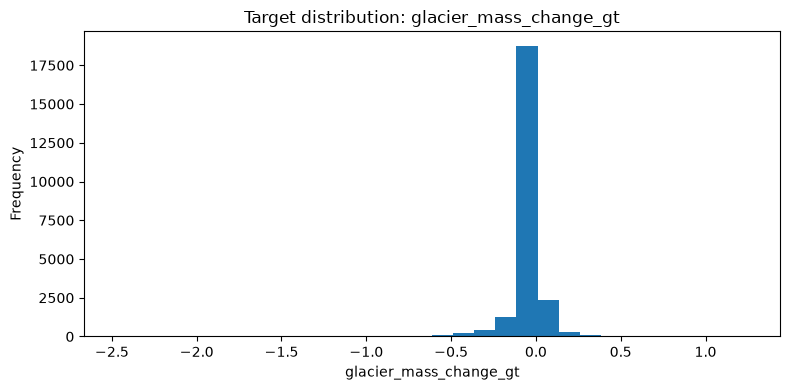

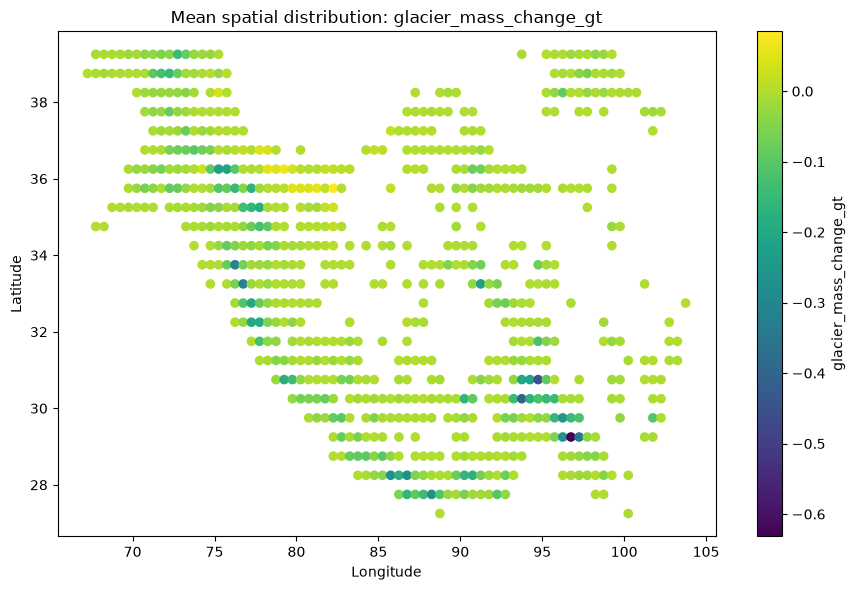

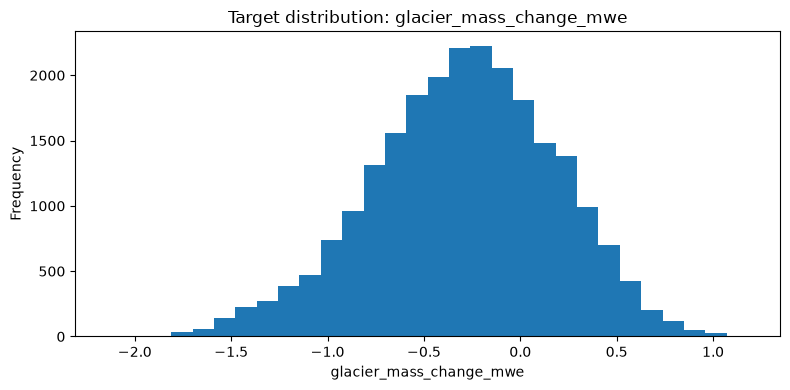

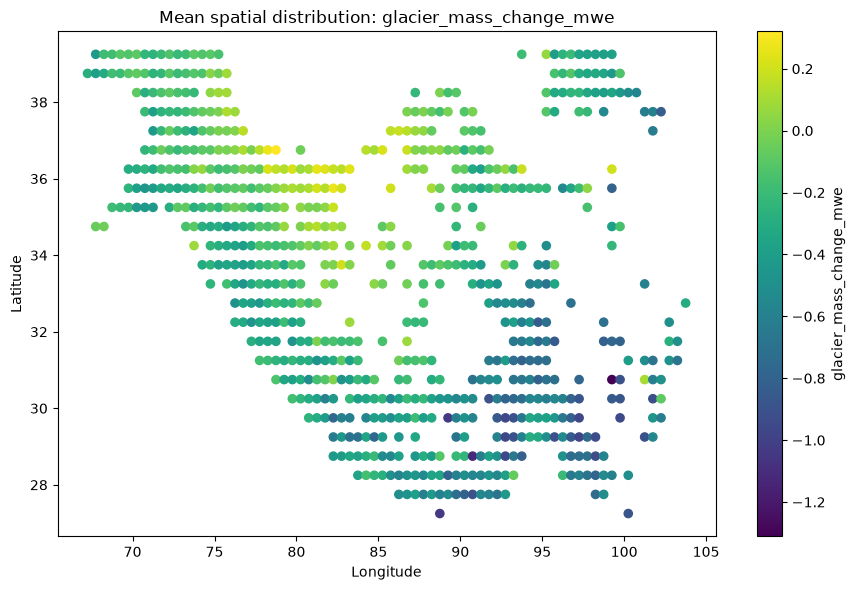

{'target': 'glacier_mass_change_gt', 'feature': 't2m', 'n': 23698, 'pearson_r': np.float64(0.08840729182450964), 'spearman_r': np.float64(0.041007851709489083)}


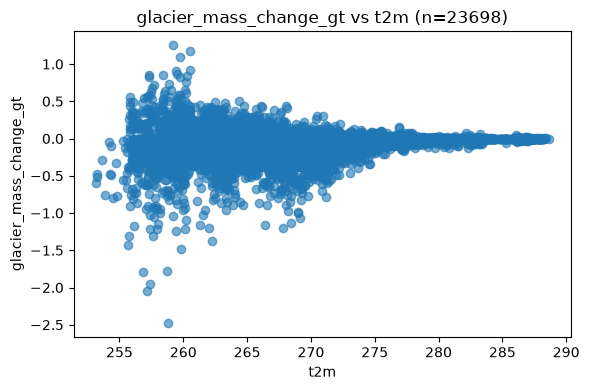

{'target': 'glacier_mass_change_gt', 'feature': 'snowc', 'n': 23698, 'pearson_r': np.float64(-0.22904320633737937), 'spearman_r': np.float64(-0.2585129358790077)}


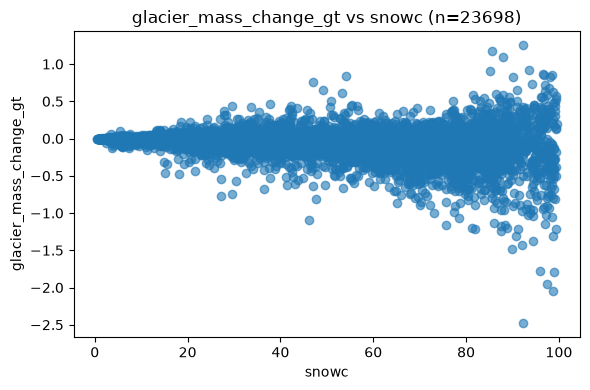

{'target': 'glacier_mass_change_gt', 'feature': 'sde', 'n': 23698, 'pearson_r': np.float64(-0.2741672706275428), 'spearman_r': np.float64(-0.28601512875118373)}


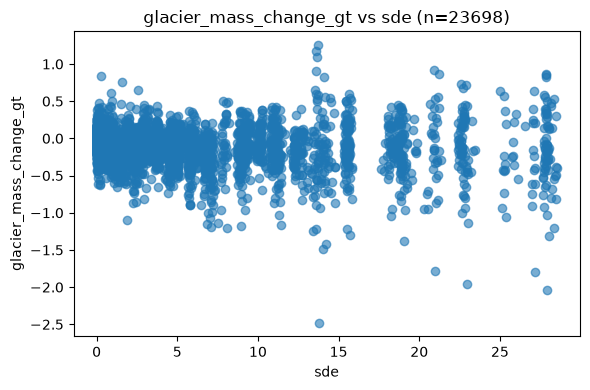

{'target': 'glacier_mass_change_gt', 'feature': 'sd', 'n': 23698, 'pearson_r': np.float64(-0.2724220340476494), 'spearman_r': np.float64(-0.2825254898140461)}


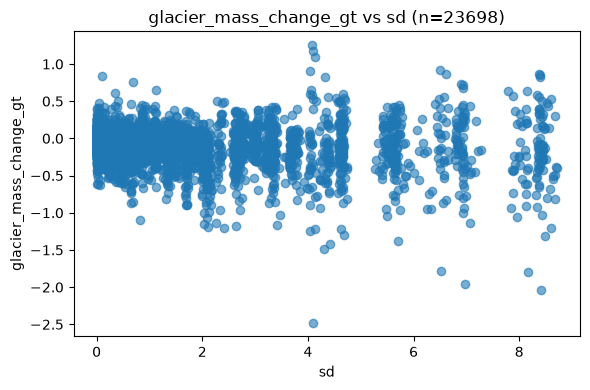

{'target': 'glacier_mass_change_gt', 'feature': 'sf', 'n': 23698, 'pearson_r': np.float64(-0.21258207681694835), 'spearman_r': np.float64(-0.2642461304831648)}


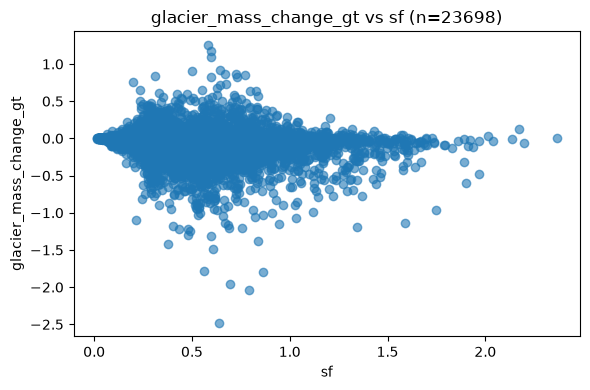

{'target': 'glacier_mass_change_gt', 'feature': 'smlt', 'n': 23698, 'pearson_r': np.float64(-0.18085056771815763), 'spearman_r': np.float64(-0.25809290455349604)}


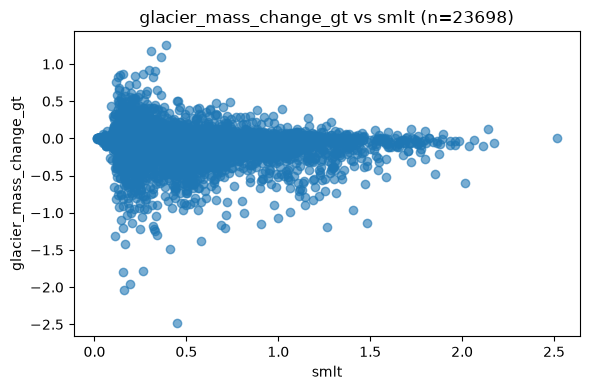

{'target': 'glacier_mass_change_gt', 'feature': 'ssr', 'n': 23698, 'pearson_r': np.float64(0.24811190419420492), 'spearman_r': np.float64(0.2660618005795117)}


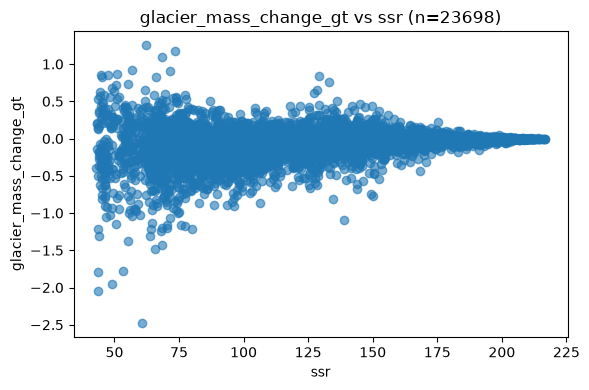

{'target': 'glacier_mass_change_gt', 'feature': 'str', 'n': 23698, 'pearson_r': np.float64(-0.21455840348839936), 'spearman_r': np.float64(-0.27418269670754003)}


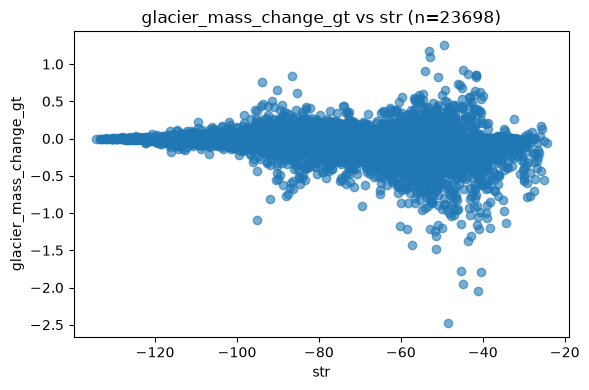

{'target': 'glacier_mass_change_gt', 'feature': 'ro', 'n': 23698, 'pearson_r': np.float64(-0.1149946528331625), 'spearman_r': np.float64(-0.2838548187163543)}


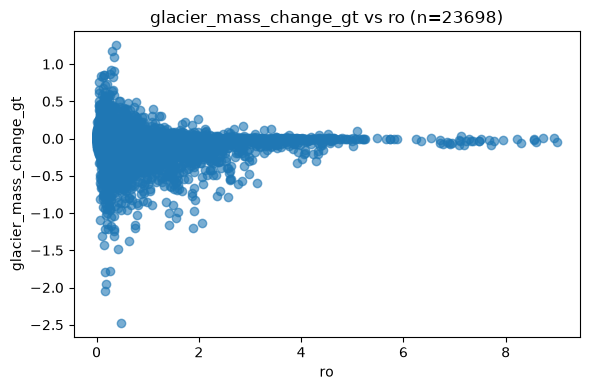

{'target': 'glacier_mass_change_gt', 'feature': 'es', 'n': 23698, 'pearson_r': np.float64(-0.09017376046175926), 'spearman_r': np.float64(-0.08135766244838939)}


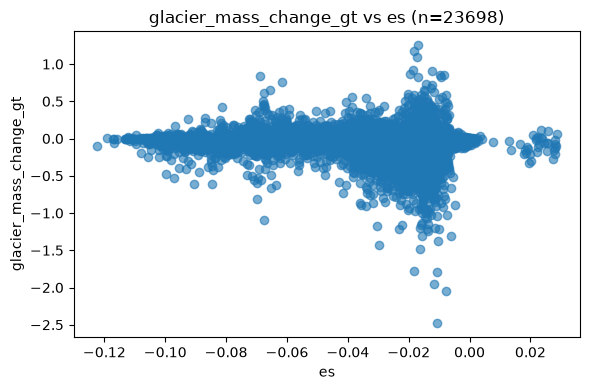

{'target': 'glacier_mass_change_gt', 'feature': 'sro', 'n': 23698, 'pearson_r': np.float64(-0.12789060585889395), 'spearman_r': np.float64(-0.2773484508112265)}


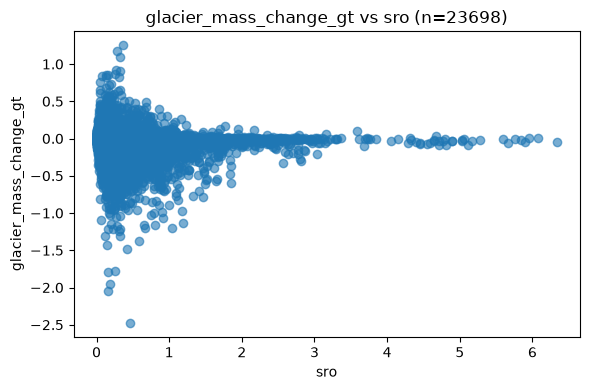

{'target': 'glacier_mass_change_gt', 'feature': 'e', 'n': 23698, 'pearson_r': np.float64(-0.16118605392696073), 'spearman_r': np.float64(-0.08797954407234712)}


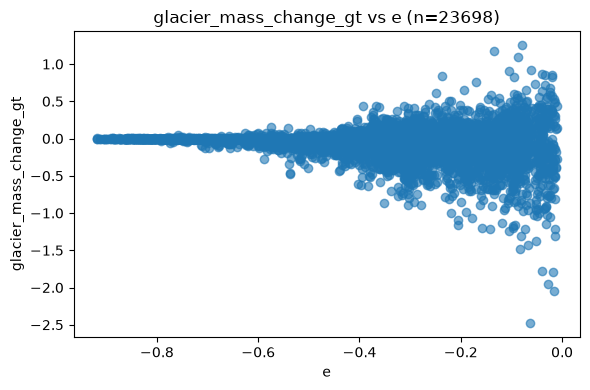

{'target': 'glacier_mass_change_gt', 'feature': 'u10', 'n': 23698, 'pearson_r': np.float64(0.12271894093394743), 'spearman_r': np.float64(0.15845021538840542)}


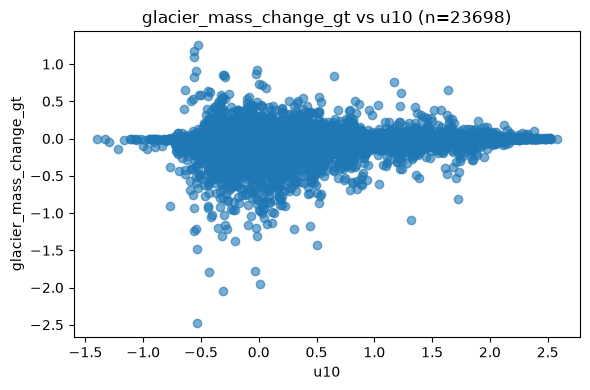

{'target': 'glacier_mass_change_gt', 'feature': 'v10', 'n': 23698, 'pearson_r': np.float64(0.04080964248188521), 'spearman_r': np.float64(0.01277235289385536)}


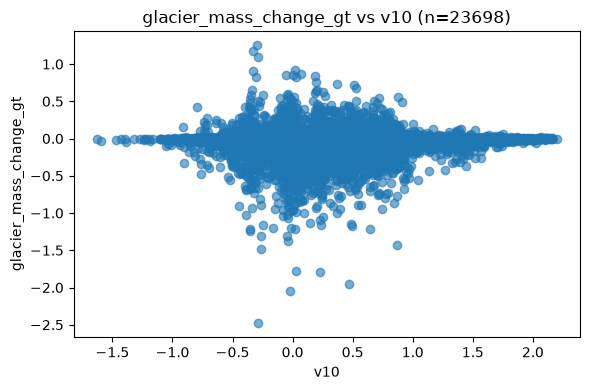

{'target': 'glacier_mass_change_gt', 'feature': 'tp', 'n': 23698, 'pearson_r': np.float64(-0.09311896265603752), 'spearman_r': np.float64(-0.23965449471785755)}


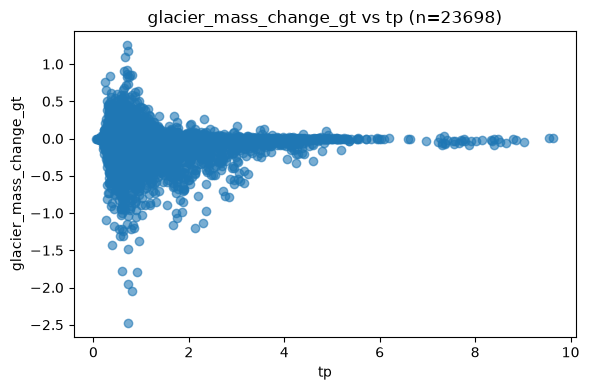

{'target': 'glacier_mass_change_mwe', 'feature': 't2m', 'n': 23698, 'pearson_r': np.float64(-0.11944239056603755), 'spearman_r': np.float64(-0.1479643035068031)}


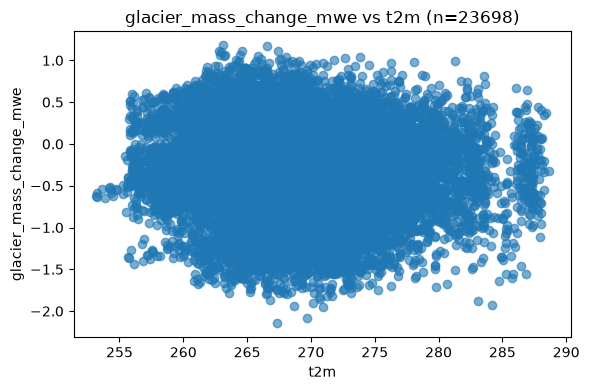

{'target': 'glacier_mass_change_mwe', 'feature': 'snowc', 'n': 23698, 'pearson_r': np.float64(-0.05958897035540334), 'spearman_r': np.float64(-0.06570067808974414)}


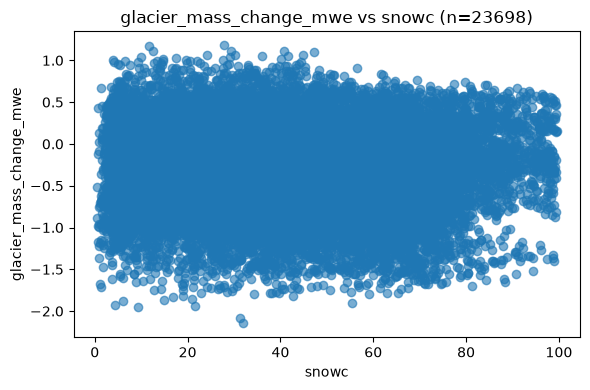

{'target': 'glacier_mass_change_mwe', 'feature': 'sde', 'n': 23698, 'pearson_r': np.float64(0.037921214823119484), 'spearman_r': np.float64(-0.08051517288163205)}


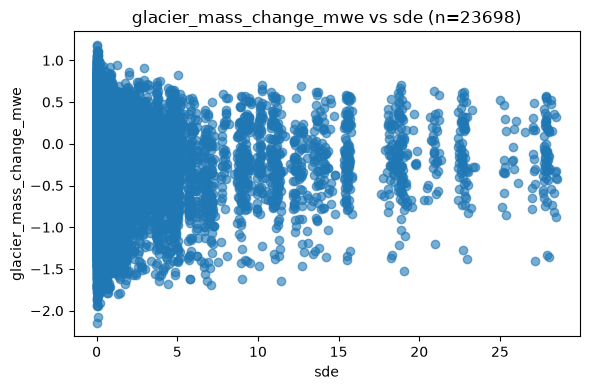

{'target': 'glacier_mass_change_mwe', 'feature': 'sd', 'n': 23698, 'pearson_r': np.float64(0.04006417533445917), 'spearman_r': np.float64(-0.08125729674949414)}


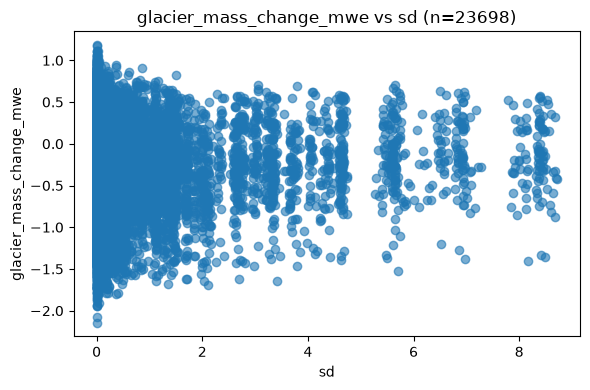

{'target': 'glacier_mass_change_mwe', 'feature': 'sf', 'n': 23698, 'pearson_r': np.float64(-0.08840587190416045), 'spearman_r': np.float64(-0.12331866419848632)}


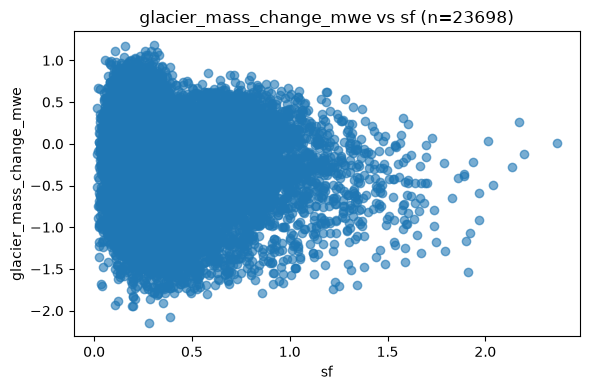

{'target': 'glacier_mass_change_mwe', 'feature': 'smlt', 'n': 23698, 'pearson_r': np.float64(-0.121376570159324), 'spearman_r': np.float64(-0.1635829553163589)}


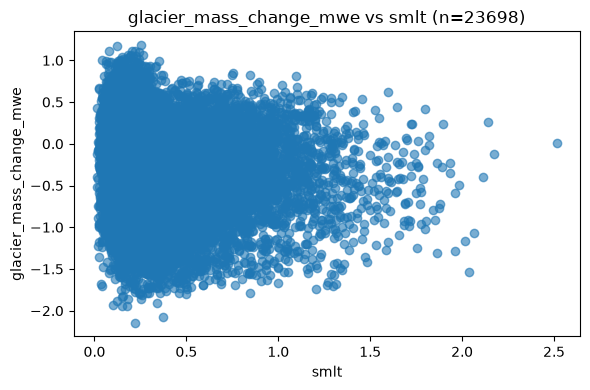

{'target': 'glacier_mass_change_mwe', 'feature': 'ssr', 'n': 23698, 'pearson_r': np.float64(0.06398278825216049), 'spearman_r': np.float64(0.07987011218265713)}


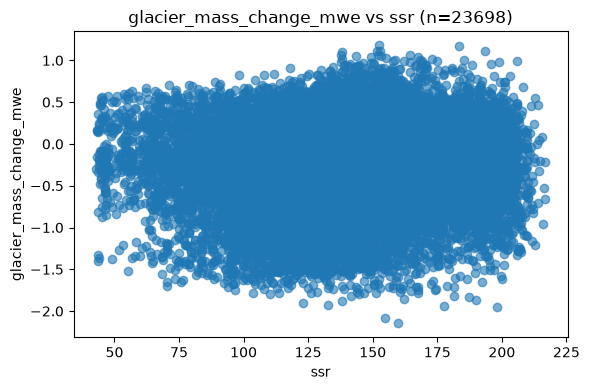

{'target': 'glacier_mass_change_mwe', 'feature': 'str', 'n': 23698, 'pearson_r': np.float64(-0.19939733894488693), 'spearman_r': np.float64(-0.19709780960545786)}


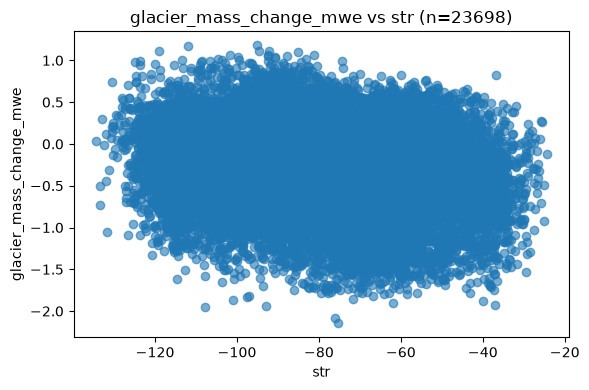

{'target': 'glacier_mass_change_mwe', 'feature': 'ro', 'n': 23698, 'pearson_r': np.float64(-0.20580101963143), 'spearman_r': np.float64(-0.32131010235943525)}


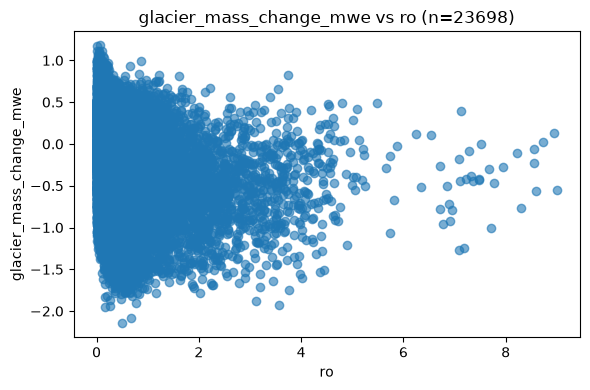

{'target': 'glacier_mass_change_mwe', 'feature': 'es', 'n': 23698, 'pearson_r': np.float64(-0.06514871573181638), 'spearman_r': np.float64(-0.05043612042008291)}


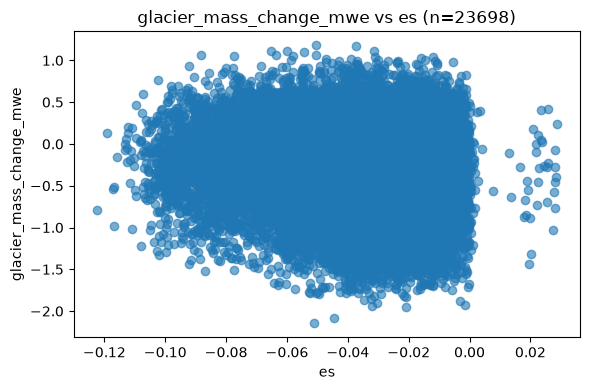

{'target': 'glacier_mass_change_mwe', 'feature': 'sro', 'n': 23698, 'pearson_r': np.float64(-0.12968018204761603), 'spearman_r': np.float64(-0.2121021348382853)}


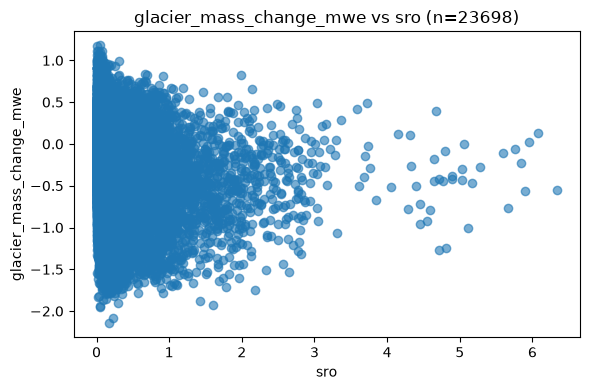

{'target': 'glacier_mass_change_mwe', 'feature': 'e', 'n': 23698, 'pearson_r': np.float64(0.16925640801783812), 'spearman_r': np.float64(0.1769399251749186)}


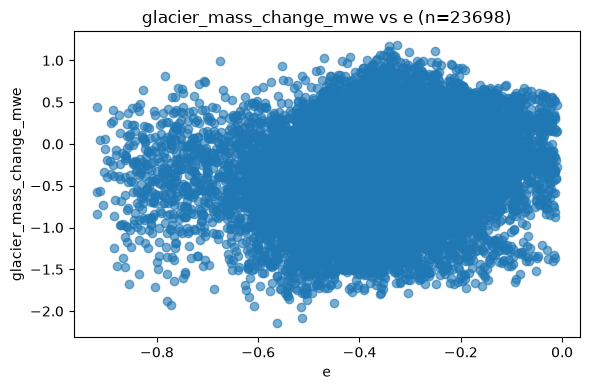

{'target': 'glacier_mass_change_mwe', 'feature': 'u10', 'n': 23698, 'pearson_r': np.float64(0.18470497389574808), 'spearman_r': np.float64(0.15579729636943004)}


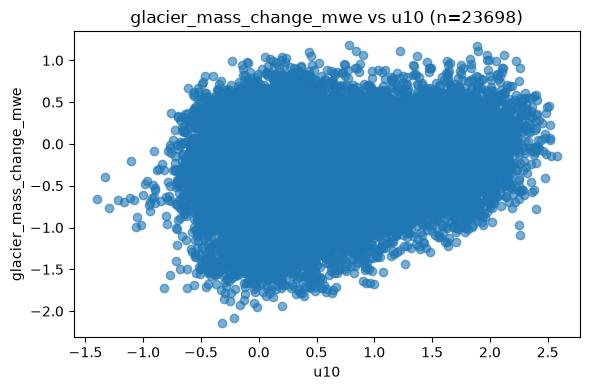

{'target': 'glacier_mass_change_mwe', 'feature': 'v10', 'n': 23698, 'pearson_r': np.float64(-0.06696094464140082), 'spearman_r': np.float64(-0.06794198782415942)}


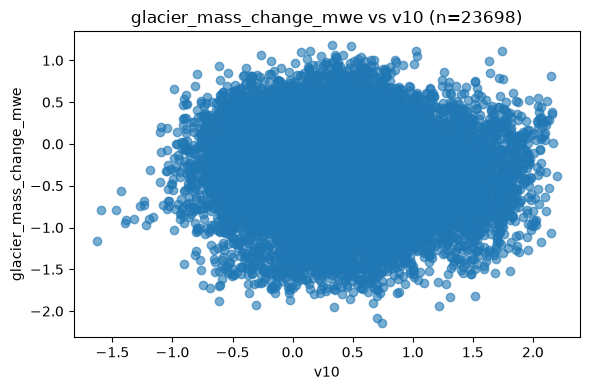

{'target': 'glacier_mass_change_mwe', 'feature': 'tp', 'n': 23698, 'pearson_r': np.float64(-0.21464033216527448), 'spearman_r': np.float64(-0.3215433399387919)}


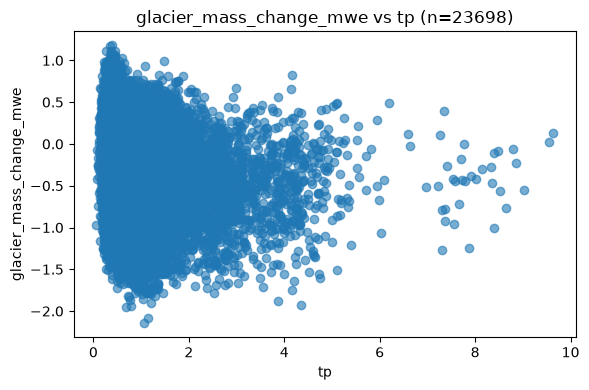

In [16]:
available_targets = [c for c in TARGET_VALUE_COLS if c in integrated_all.columns]
if not available_targets:
    print("No configured target value columns were found. Inspect the target schema and update TARGET_VALUE_COLS in Section 1.")
else:
    display(integrated_all[available_targets].describe().T)
    for col in available_targets:
        vals = pd.to_numeric(integrated_all[col], errors="coerce").dropna()
        if len(vals):
            plt.figure(figsize=(8,4)); plt.hist(vals, bins=30)
            plt.title(f"Target distribution: {col}"); plt.xlabel(col); plt.ylabel("Frequency")
            plt.tight_layout(); plt.show()
            spatial = integrated_all[["target_longitude", "target_latitude", col]].copy()
            spatial[col] = pd.to_numeric(spatial[col], errors="coerce")
            spatial = spatial.dropna().groupby(["target_longitude", "target_latitude"], as_index=False)[col].mean()
            plt.figure(figsize=(9,6)); sc = plt.scatter(spatial["target_longitude"], spatial["target_latitude"], c=spatial[col], s=35)
            plt.colorbar(sc, label=col); plt.xlabel("Longitude"); plt.ylabel("Latitude")
            plt.title(f"Mean spatial distribution: {col}"); plt.tight_layout(); plt.show()

if available_targets and annual_vars:
    for y in available_targets:
        for x in annual_vars:
            pair = integrated_all[[y, x]].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
            if len(pair) >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
                print({"target": y, "feature": x, "n": len(pair),
                       "pearson_r": pair.corr(method="pearson").iloc[0,1],
                       "spearman_r": pair.corr(method="spearman").iloc[0,1]})
                plt.figure(figsize=(6,4)); plt.scatter(pair[x], pair[y], alpha=.6)
                plt.xlabel(x); plt.ylabel(y); plt.title(f"{y} vs {x} (n={len(pair)})")
                plt.tight_layout(); plt.show()

## 15. Export auditable outputs without overwriting existing files

The notebook writes output files with timestamped names if a previous output already exists. It exports filtered-source diagnostics, overlap geometry, monthly climate data, annual climate features, integrated target rows, metadata, and period mapping. Original source CSVs are never modified.

In [17]:
def safe_output_path(filename):
    p = OUTPUT_DIR / filename
    if not p.exists():
        return p
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    return OUTPUT_DIR / f"{p.stem}_{stamp}{p.suffix}"

def export_csv(df, filename):
    p = safe_output_path(filename)
    df.to_csv(p, index=False)
    print("Saved:", p, "rows:", len(df))
    return p

# Audits
source_file_audit = pd.DataFrame([
    {**file_info(TARGET_PATH), "dataset": "target"},
    {**file_info(ERA5_PATH), "dataset": "ERA5-Land original source CSV (streamed)"},
    {**file_info(CORRECTED_PATH), "dataset": "ERA5-Land corrected 00:00 source CSV"}
])

def missingness_audit(df, name):
    return pd.DataFrame({
        "dataset": name, "column": df.columns, "dtype": df.dtypes.astype(str).values,
        "missing_count": [int(df[c].isna().sum()) for c in df.columns],
        "missing_percent": [float(df[c].isna().mean()*100) for c in df.columns],
        "unique_count": [int(df[c].nunique(dropna=True)) for c in df.columns]
    })

export_csv(source_file_audit, "hkh_source_file_audit.csv")
export_csv(missingness_audit(target, "target"), "target_source_missingness_audit.csv")
export_csv(missingness_audit(era_region, "ERA5-Land filtered target-overlap subset"), "era5_filtered_source_missingness_audit.csv")
export_csv(variable_metadata, "hkh_era5land_feature_metadata.csv")
export_csv(geometry_coverage, "era5land_to_glacier_grid_overlap_diagnostics.csv")
export_csv(monthly_spatial, "era5land_hkh_conservative_regridded_monthly.csv")
if "annual_climate" in globals():
    export_csv(annual_climate, "era5land_hkh_conservative_regridded_hydrological_year.csv")
if "integrated_all" in globals():
    export_csv(integrated_all, "hkh_glacier_mass_change_era5land_hydrological_year_eda.csv")
export_csv(target_periodized[["target_year_label", "period_start", "period_end_exclusive"]].drop_duplicates().sort_values("target_year_label"),
           "hkh_glacier_hydrological_year_mapping.csv")
export_csv(month_counts, "hkh_monthly_completeness_by_cell_year.csv")
export_csv(correction_audit, "era5land_correction_replacement_audit.csv")

if "post_regrid_correction_audit" in globals():
    export_csv(post_regrid_correction_audit, "era5land_post_regridding_correction_audit.csv")


Saved: E:\glacier_research\processed_data\hkh_source_file_audit.csv rows: 3
Saved: E:\glacier_research\processed_data\target_source_missingness_audit.csv rows: 9
Saved: E:\glacier_research\processed_data\era5_filtered_source_missingness_audit.csv rows: 19
Saved: E:\glacier_research\processed_data\hkh_era5land_feature_metadata.csv rows: 15
Saved: E:\glacier_research\processed_data\era5land_to_glacier_grid_overlap_diagnostics.csv rows: 697
Saved: E:\glacier_research\processed_data\era5land_hkh_conservative_regridded_monthly.csv rows: 284376
Saved: E:\glacier_research\processed_data\era5land_hkh_conservative_regridded_hydrological_year.csv rows: 23698
Saved: E:\glacier_research\processed_data\hkh_glacier_mass_change_era5land_hydrological_year_eda.csv rows: 23698
Saved: E:\glacier_research\processed_data\hkh_glacier_hydrological_year_mapping.csv rows: 34
Saved: E:\glacier_research\processed_data\hkh_monthly_completeness_by_cell_year.csv rows: 23698
Saved: E:\glacier_research\processed_data

## 16. Final research checklist and interpretation limits

Before treating the integrated table as research-ready, confirm each item:

- [ ] Target product provenance, target units, and mass-change sign convention verified.
- [x] Researcher-confirmed mapping applied: target year 1991 = April 1990–March 1991.
- [ ] Target geographic extent matches the intended HKH study region; explain why the target filename says “nepal” if coordinates extend beyond Nepal.
- [ ] Grid-cell bounds checked against authoritative NetCDF bounds where available.
- [ ] Geometry coverage threshold chosen after reviewing actual diagnostics; a 0.70 threshold does not mean full coverage.
- [ ] Source ERA5 rows were streamed and filtered; the full original CSV was not loaded into one DataFrame.
- [ ] Duplicate ERA time/source-cell keys investigated; source metadata such as `expver` verified against source provenance.
- [ ] **Correction audit passes:** 18 months from September 2022 through February 2024; all 12 corrected variables have zero missing regional month/grid replacements.
- [ ] `snowc`, `sde`, and `sd` retained from the original source and checked for completeness in the correction window.
- [ ] ERA5-Land units and temporal semantics checked from original NetCDF metadata, especially the corrected monthly-averaged-by-hour-of-day recovery product. Do not assume values are interchangeable with `moda` without verifying ECMWF guidance.
- [ ] Annual aggregation operations and output units approved for each variable; the current metadata table is a review aid, not proof that every operation is scientifically verified.
- [ ] Per-variable monthly coverage and annual completeness reviewed. Annual features with missing months are NaN by design rather than silently imputed.
- [ ] Unmatched target rows preserved and explained.
- [ ] Output row counts, distributions, and limitations reviewed.

**Important:** the correction join uses year-month and rounded grid coordinates, not exact timestamps, because corrected CSV timestamps can be on day 2. The audit confirms join coverage but does not independently certify the physical meaning/units of the recovery product. This notebook integrates data and performs EDA; it does not train a glacier mass-balance model. Same-hydrological-year climate features are retrospective and are not automatically valid predictors for a forecast made before that year ends.
